# Phân tích khám phá dữ liệu chữ viết tay — VietHTR-line (viet_htr)

Notebook độc lập, phân tích trực tiếp **`data/viet_htr`**. Chọn kernel Python đã cài thư viện,
sau đó **Restart Kernel → Run All**. Mọi số liệu và nhận xét định lượng được tính từ dữ liệu trên máy;
không điền số mẫu hoặc kết luận giả định. Không chỉnh sửa dữ liệu gốc.

**Nội dung:** (1) nguồn và kiểm kê; (2) chất lượng nhãn/Unicode; (3) phân phối độ dài;
(4) từ vựng và dấu tiếng Việt; (5) hình học ảnh; (6) chỉ báo chất lượng và ảnh minh họa;
(7) dữ liệu trùng và giao train/test; (8) dịch chuyển phân phối và ký tự chưa gặp;
(9) tác động đến resize, padding, CTC; (10) kết luận tự động và xuất bảng/hình;
(11) so sánh với bộ dữ liệu còn lại.

**Quy ước:** một mẫu là một ảnh dòng chữ và một nhãn. Độ dài ký tự là số Unicode code point
sau NFC, gồm cả khoảng trắng, không phải số grapheme cluster. Token cách trắng và token chữ
trong tiếng Việt thường tương ứng âm tiết, **không được diễn giải là từ đã tách ngữ nghĩa**.
Train/test giữ nguyên theo bản dữ liệu cục bộ. Không dùng thống kê test để tự động thay đổi train.

## 1. Môi trường, đường dẫn và phương pháp

Nếu thiếu thư viện, bỏ dấu `#` ở dòng `%pip` và chạy một lần, sau đó khởi động lại kernel.
`pyarrow` đọc trực tiếp định dạng Arrow của Hugging Face, không cần tải dữ liệu hoặc cài `datasets`.
Các biểu đồ được nhúng trong notebook và đồng thời lưu PNG 160 dpi; bảng được lưu CSV UTF-8 BOM
để mở bằng Excel. Seed cố định giúp lặp lại việc chọn ảnh minh họa.

In [1]:
# %pip install numpy pandas matplotlib pillow pyarrow scipy tqdm
import sys, io, json, re, math, hashlib, platform, unicodedata, warnings
from pathlib import Path
from collections import Counter
from datetime import datetime, timezone
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
import pyarrow as pa
import pyarrow.ipc as ipc
from scipy.stats import ks_2samp, spearmanr
from scipy.spatial.distance import jensenshannon
from tqdm.auto import tqdm
from IPython.display import display, Markdown

D:\2026_1\deep_learning\ocr-vietnamese\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
DATASET = 'viet_htr'
# Có thể gán PROJECT_ROOT = Path(r"D:/.../ocr-vietnamese") khi đặt notebook ở nơi khác.
PROJECT_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                     if (p / 'data' / DATASET).is_dir()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError(f'Không tìm thấy data/{DATASET} từ {Path.cwd()}. Hãy đặt PROJECT_ROOT.')
DATA_ROOT = PROJECT_ROOT / 'data' / DATASET
REPORT_DIR = PROJECT_ROOT / 'reports' / 'results' / 'eda' / DATASET
FIG_DIR = REPORT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
SEED = 2026
IMAGE_LIMIT = None  # None: kiểm tra TẤT CẢ ảnh; số nguyên: giới hạn tổng ảnh, lấy mẫu theo split.
TARGET_HEIGHT = 32
QUALITY_SIZE = (512, 128)  # thumbnail giữ tỷ lệ; chỉ dùng cho các proxy chất lượng.
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 10,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'axes.grid': True, 'grid.alpha': .18})
COLORS = {'train': '#2266AA', 'test': '#DA7B22', 'validation': '#339977'}
FIGURES = []
def finish(fig, name):
    fig.tight_layout()
    fig.savefig(FIG_DIR / f'{name}.png', dpi=160, bbox_inches='tight')
    FIGURES.append(name)
    plt.show()
    plt.close(fig)
def table(frame, name=None, n=25):
    if name:
        frame.to_csv(REPORT_DIR / f'{name}.csv', index=False, encoding='utf-8-sig')
    display(frame.head(n))
def note(s):
    display(Markdown(s))
versions = {p: metadata.version(p) for p in
            ['numpy', 'pandas', 'matplotlib', 'pillow', 'pyarrow', 'scipy', 'tqdm']}
display(pd.Series({'python': sys.version.split()[0], 'dataset': str(DATA_ROOT),
                   'image_limit': IMAGE_LIMIT, **versions}, name='Cấu hình'))

python                                                   3.12.10
dataset        D:\2026_1\deep_learning\ocr-vietnamese\data\vi...
image_limit                                                  NaN
numpy                                                      2.5.1
pandas                                                     3.0.3
matplotlib                                                3.11.2
pillow                                                    13.0.0
pyarrow                                                   26.0.0
scipy                                                     1.18.1
tqdm                                                      4.70.1
Name: Cấu hình, dtype: str

## 2. Kiểm kê cấu trúc và đọc nhãn

Đọc mọi nhãn của mọi split trước khi xử lý ảnh. Lỗi đọc, nhãn sai kiểu, nhãn rỗng và ảnh lỗi
được giữ lại để báo cáo; không âm thầm loại bỏ. Mã mẫu gồm split và vị trí nguồn để có thể truy vết.

In [3]:
dict_path = DATA_ROOT / 'dataset_dict.json'
if not dict_path.is_file():
    raise FileNotFoundError(f'Không tìm thấy {dict_path}; cần thư mục save_to_disk của Hugging Face.')
split_names = json.loads(dict_path.read_text(encoding='utf-8')).get('splits', [])
if not split_names:
    raise ValueError('dataset_dict.json không có split.')
records, inventory, issues, arrow_sources, local_metadata = [], [], [], [], {}
for split in split_names:
    split_root = DATA_ROOT / split
    state = json.loads((split_root / 'state.json').read_text(encoding='utf-8'))
    info_path = split_root / 'dataset_info.json'
    local_metadata[split] = json.loads(info_path.read_text(encoding='utf-8')) if info_path.exists() else {}
    shard_entries = state.get('_data_files', [])
    if not shard_entries:
        raise ValueError(f'{split}: state.json không liệt kê shard nào.')
    offset = 0
    for item in shard_entries:
        shard = (split_root / item['filename']).resolve()
        if not shard.is_relative_to(DATA_ROOT.resolve()):
            raise ValueError(f'Shard nằm ngoài DATA_ROOT: {shard}')
        mmap = pa.memory_map(str(shard), 'r')
        try:
            reader = ipc.open_stream(mmap)
        except pa.ArrowInvalid:
            mmap.seek(0)
            reader = ipc.open_file(mmap)
        arrow_table = reader.read_all()
        if not {'image', 'text'}.issubset(arrow_table.column_names):
            raise ValueError(f'{shard.name}: thiếu cột image/text: {arrow_table.schema}')
        source_index = len(arrow_sources)
        # Giữ mmap sống; không chuyển cả cột ảnh ~GB sang list Python.
        arrow_sources.append({'table': arrow_table, 'mmap': mmap, 'path': shard})
        inventory.append({'split': split, 'shard': shard.name, 'rows': len(arrow_table),
                          'bytes_on_disk': shard.stat().st_size})
        texts = arrow_table['text'].to_pylist()
        for i, text in enumerate(texts):
            ok = isinstance(text, str)
            sid = f'{split}/{offset+i:07d}'
            if not ok:
                issues.append(('invalid_label_type', sid, type(text).__name__))
            records.append({'sample_id': sid, 'split': split, 'group_id': None,
                'source_shard': shard.relative_to(DATA_ROOT).as_posix(), 'source_row': i,
                'source_index': source_index, 'row_in_split': offset+i,
                'text_raw': text if ok else '', 'label_valid': ok})
        offset += len(arrow_table)
df = pd.DataFrame(records)
def get_image_bytes(row):
    cell = arrow_sources[int(row.source_index)]['table']['image'][int(row.source_row)].as_py()
    if not isinstance(cell, dict):
        raise ValueError('Image Arrow bị null hoặc sai cấu trúc')
    if cell.get('bytes') is not None:
        return cell['bytes']
    if not cell.get('path'):
        raise FileNotFoundError('Ảnh không có embedded bytes hoặc đường dẫn')
    raw_path = Path(cell['path'])
    shard = arrow_sources[int(row.source_index)]['path']
    candidates = [raw_path] if raw_path.is_absolute() else [
        shard.parent / raw_path, DATA_ROOT / raw_path, PROJECT_ROOT / raw_path]
    for candidate in candidates:
        if candidate.is_file():
            return candidate.read_bytes()
    raise FileNotFoundError(f'Không tìm thấy ảnh tham chiếu: {cell["path"]}')
table(pd.DataFrame([{'split': s, 'features': json.dumps(info.get('features', {}), ensure_ascii=False),
                    'license': info.get('license', ''), 'homepage': info.get('homepage', ''),
                    'description': info.get('description', '')} for s, info in local_metadata.items()]),
      'local_dataset_metadata')

,split,features,license,homepage,description
0,train,"{""image"": {""_type"": ""Image""}, ""text"": {""dtype""...",,,
1,test,"{""image"": {""_type"": ""Image""}, ""text"": {""dtype""...",,,


### Cách hiểu cấu trúc viet_htr

Thư mục là bản `DatasetDict.save_to_disk`: split lấy từ `dataset_dict.json`, thứ tự shard lấy đúng
từ `state.json`, gồm cột `image` và `text`. Ảnh nhúng bytes được ưu tiên; nếu chỉ có đường dẫn
thì thử vị trí gốc hoặc đường dẫn tương đối với shard/dataset/dự án.
Không tải lại Hugging Face, không giả định số shard cố định, không giải mã cả cột ảnh vào RAM.
Metadata chỉ có `image/text` thì không có căn cứ để suy ra người viết, trang hay tính độc lập theo người viết.
Trường license/homepage trống được giữ nguyên, không tự điền nguồn hoặc giấy phép.

,split,n_samples,percent
0,train,59247,98.340166
1,test,1000,1.659834


,split,shard,rows,bytes_on_disk
0,train,data-00000-of-00003.arrow,19749,387471864
1,train,data-00001-of-00003.arrow,19749,386085904
2,train,data-00002-of-00003.arrow,19749,478269744
3,test,data-00000-of-00001.arrow,1000,20736208


,kind,source,detail


,sample_id,split,group_id,text_raw
22062,train/0022062,train,None,Các thùng xấp dọc phân đất gia đình bà Thương
6772,train/0006772,train,None,Bài 3 Phân tích cấu tạo của mỗi tiếng và điền ...
32890,train/0032890,train,None,khổ. Mẹ đi chợ về mà con lại nhiễu với mẹ
9700,train/0009700,train,None,Bài 3: Lượng nước trong hạt tươi chiếm
4384,train/0004384,train,None,Biết phấn đấu cho tương lai và hiếu
17338,train/0017338,train,None,Lần sau có chép bài ai thì hãy


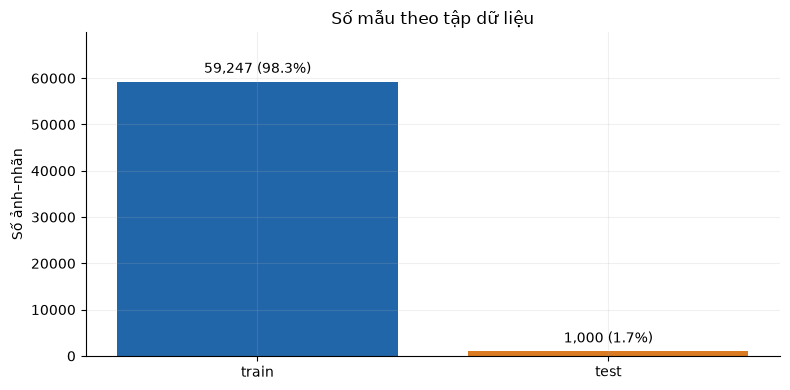

Có **60,247 bản ghi nhãn** và **0 vấn đề cấu trúc** được ghi nhận. Số ảnh đọc thành công sẽ được thống kê riêng sau khi giải mã ảnh.

In [4]:
assert len(df) > 0, 'Không có bản ghi. Hãy kiểm tra DATA_ROOT.'
assert df['sample_id'].is_unique, 'Mã mẫu trùng: cần kiểm tra lại loader.'
SPLITS = [s for s in ['train', 'validation', 'test'] if s in set(df.split)]
SPLITS += sorted(set(df.split) - set(SPLITS))
split_counts = df.groupby('split').size().reindex(SPLITS).rename('n_samples').reset_index()
split_counts['percent'] = 100 * split_counts.n_samples / len(df)
table(split_counts, 'split_counts')
table(pd.DataFrame(inventory), 'source_inventory')
audit = pd.DataFrame(issues, columns=['kind', 'source', 'detail'])
table(audit, 'source_issues')
table(df[['sample_id', 'split', 'group_id', 'text_raw']].sample(min(6, len(df)), random_state=SEED),
      'label_examples')
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(split_counts.split, split_counts.n_samples,
              color=[COLORS.get(s, '#777777') for s in split_counts.split])
ax.bar_label(bars, labels=[f'{n:,} ({p:.1f}%)' for n, p in
                         zip(split_counts.n_samples, split_counts.percent)], padding=4)
ax.set(title='Số mẫu theo tập dữ liệu', ylabel='Số ảnh–nhãn')
ax.margins(y=.18)
finish(fig, '01_split_counts')
note(f'Có **{len(df):,} bản ghi nhãn** và **{len(audit):,} vấn đề cấu trúc** được ghi nhận. '
     'Số ảnh đọc thành công sẽ được thống kê riêng sau khi giải mã ảnh.')

## 3. Chất lượng nhãn và chuẩn hóa Unicode

Giữ `text_raw` nguyên bản; tạo `text_nfc` để so sánh thống nhất cách mã hóa dấu.
`text_compare` chỉ thêm bước gộp khoảng trắng, **không bỏ dấu, không đổi chữ hoa/thường**.
Các cờ là tín hiệu cần kiểm tra thủ công, không phải quy tắc xóa dữ liệu. NFC thay đổi cách mã hóa
không đồng nghĩa nhãn sai. Cột `label_valid` chỉ xác nhận nhãn gốc có kiểu chuỗi.

Nhãn:   0%|          | 0/60247 [00:00<?, ?it/s]

Nhãn:   3%|▎         | 1612/60247 [00:00<00:03, 15966.60it/s]

Nhãn:   5%|▌         | 3209/60247 [00:00<00:03, 15275.00it/s]

Nhãn:   8%|▊         | 4739/60247 [00:00<00:03, 15163.95it/s]

Nhãn:  11%|█         | 6330/60247 [00:00<00:03, 15405.05it/s]

...

Nhãn:  96%|█████████▌| 57871/60247 [00:03<00:00, 17658.32it/s]

Nhãn:  99%|█████████▉| 59664/60247 [00:03<00:00, 17709.65it/s]

Nhãn: 100%|██████████| 60247/60247 [00:03<00:00, 17270.79it/s]

split,flag,train,test
0,empty_label,0,0
1,nfc_changed,1,0
2,outer_whitespace,0,0
3,repeated_whitespace,130,2
4,has_control,15,0
5,has_replacement,0,0


,sample_id,label_valid,text_raw,empty_label,nfc_changed,outer_whitespace,repeated_whitespace,has_control,has_replacement
1194,train/0001194,True,"xây dựng tại Ngõ 30 Kiệt 16 Duy Tân hộ ông, bà",False,False,False,True,False,False
1340,train/0001340,True,trong lao động đã để bị trong em n ấn tượng k...,False,False,False,True,False,False
1343,train/0001343,True,=> Gọi số học sinh Khối 6 của một trường,False,False,False,True,False,False
1370,train/0001370,True,- Bước 2: Phát triển nội dung:,False,False,False,True,False,False
1704,train/0001704,True,bao kết quả sản xuất. Cái nhà sàn của Bác vẻn...,False,False,False,True,False,False
2245,train/0002245,True,nhiệm của dân và quan trên phó thác quyết triệu,False,False,False,True,False,False
2291,train/0002291,True,"đấy em | Khó, tần tảo của người phụ nữ nói ch...",False,False,False,True,False,False
2689,train/0002689,True,Họ ham chơi & chủ quan vào năng lực,False,False,False,True,False,False
3725,train/0003725,True,5. Quỹ đầu tư phát triển: 600,False,False,False,True,False,False
3863,train/0003863,True,Do D là trực tâm của △BNC=>BD là đường cao học...,False,False,False,True,False,False


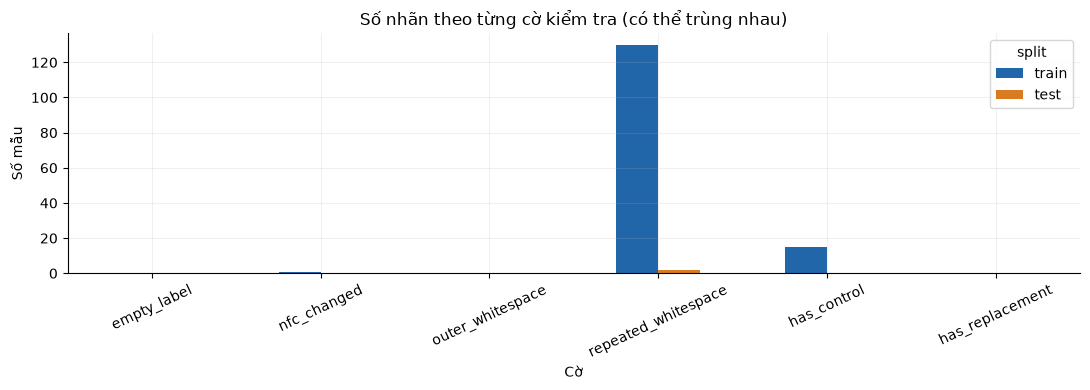

In [5]:
TONE_MARKS = {'\u0300': 'huyền', '\u0301': 'sắc', '\u0309': 'hỏi',
              '\u0303': 'ngã', '\u0323': 'nặng'}
def label_features(raw):
    text = unicodedata.normalize('NFC', raw)
    letters = [c for c in text if c.isalpha()]
    toned = sum(any(m in unicodedata.normalize('NFD', c) for m in TONE_MARKS) for c in letters)
    marked = sum(c in 'đĐ' or any(unicodedata.combining(m) for m in
                 unicodedata.normalize('NFD', c)) for c in letters)
    controls = [c for c in raw if unicodedata.category(c) in {'Cc', 'Cf'}]
    return {
        'text_nfc': text, 'text_compare': ' '.join(text.split()),
        'n_chars_raw': len(raw), 'n_chars': len(text),
        'n_tokens_ws': len(text.split()), 'n_letters': len(letters),
        'n_digits': sum(c.isdigit() for c in text),
        'n_punct': sum(unicodedata.category(c).startswith('P') for c in text),
        'n_spaces': sum(c.isspace() for c in text),
        'n_toned_letters': toned, 'n_marked_letters': marked,
        'tone_ratio': toned / max(1, len(letters)),
        'empty_label': not bool(text.strip()), 'nfc_changed': raw != text,
        'outer_whitespace': raw != raw.strip(),
        'repeated_whitespace': bool(re.search(r'\s{2,}', raw)),
        'has_control': bool(controls), 'has_replacement': '\ufffd' in raw,
        'ctc_min_steps': len(text) + sum(a == b for a, b in zip(text, text[1:])),
    }
df = pd.concat([df.reset_index(drop=True),
                pd.DataFrame([label_features(t) for t in tqdm(df.text_raw, desc='Nhãn')])], axis=1)
flag_cols = ['empty_label', 'nfc_changed', 'outer_whitespace', 'repeated_whitespace',
             'has_control', 'has_replacement']
quality_labels = df.groupby('split')[flag_cols].sum().reindex(SPLITS).T
table(quality_labels.rename_axis('flag').reset_index(), 'label_quality_flags')
table(df.loc[(~df.label_valid) | df[flag_cols].any(axis=1),
             ['sample_id', 'label_valid', 'text_raw'] + flag_cols], 'flagged_labels', 20)
fig, ax = plt.subplots(figsize=(11, 4))
quality_labels.plot.bar(ax=ax, color=[COLORS.get(s, '#777777') for s in quality_labels.columns])
ax.set(title='Số nhãn theo từng cờ kiểm tra (có thể trùng nhau)', ylabel='Số mẫu', xlabel='Cờ')
ax.tick_params(axis='x', rotation=25)
finish(fig, '02_label_quality')

## 4. Thống kê mô tả độ dài dòng chữ

Báo cáo trung bình, độ lệch chuẩn, trung vị, các phân vị, min/max; histogram dùng cùng bin giữa
các split và chuẩn hóa mật độ để dễ so sánh. ECDF thể hiện tỷ lệ mẫu có độ dài không vượt một giá trị.
Điểm nằm ngoài râu boxplot (1,5 IQR) chỉ là ngoại lệ thống kê, chưa chứng minh nhãn sai.

,split,metric,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,test,n_chars,1000.0,53.638000,16.062221,11.0,19.000000,28.000000,45.000000,52.500000,60.000000,83.000000,101.010000,166.000000
1,test,n_tokens_ws,1000.0,12.911000,3.741534,3.0,4.000000,7.000000,11.000000,13.000000,15.000000,20.000000,24.000000,37.000000
2,test,n_letters,1000.0,39.845000,12.029284,8.0,12.000000,20.950000,34.000000,39.000000,45.000000,61.000000,75.000000,121.000000
3,test,n_digits,1000.0,0.485000,1.333999,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,3.000000,6.010000,19.000000
4,test,n_punct,1000.0,1.327000,1.292184,0.0,0.000000,0.000000,0.000000,1.000000,2.000000,4.000000,6.000000,10.000000
5,test,n_toned_letters,1000.0,8.923000,3.197389,0.0,0.990000,4.000000,7.000000,9.000000,11.000000,14.000000,17.000000,22.000000
6,test,tone_ratio,1000.0,0.223768,0.050067,0.0,0.076154,0.147059,0.195122,0.225000,0.255814,0.297979,0.333333,0.407407
7,train,n_chars,59247.0,45.382332,14.924734,4.0,14.000000,22.000000,36.000000,44.000000,54.000000,72.000000,88.000000,157.000000
8,train,n_tokens_ws,59247.0,10.892906,3.539367,1.0,3.000000,5.000000,9.000000,11.000000,13.000000,17.000000,21.000000,35.000000
9,train,n_letters,59247.0,33.647780,11.335217,0.0,9.000000,16.000000,27.000000,33.000000,40.000000,53.000000,65.000000,112.000000


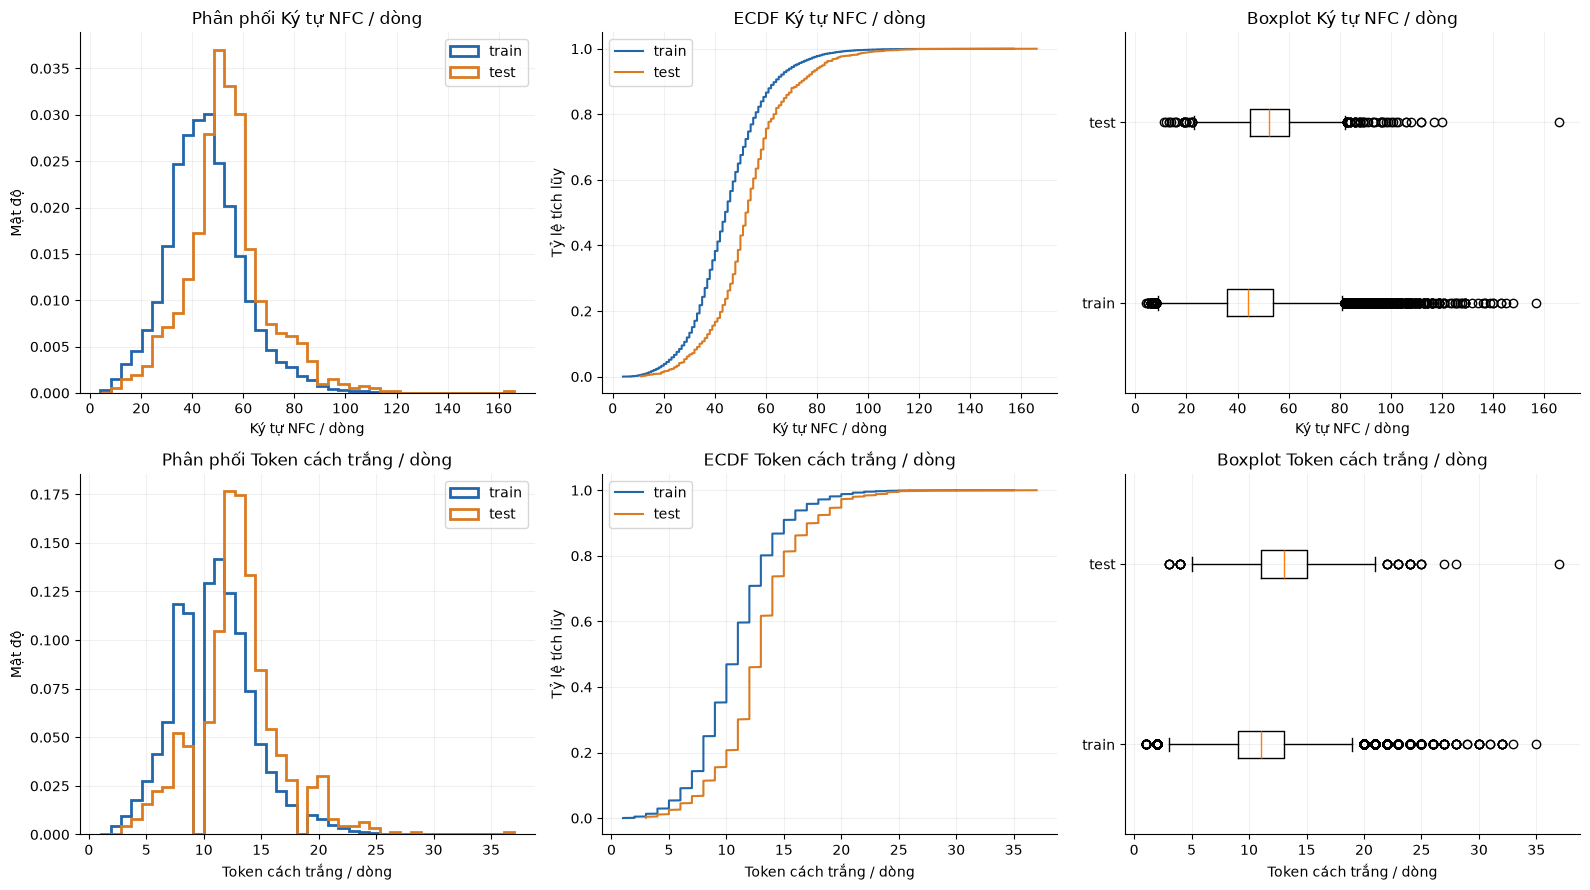

,extreme,sample_id,split,n_chars,n_tokens_ws,text_nfc
9175,ngắn nhất,train/0009175,train,4,1,time
6911,ngắn nhất,train/0006911,train,5,1,BTVN:
28270,ngắn nhất,train/0028270,train,5,3,ă ă ă
28863,ngắn nhất,train/0028863,train,5,1,Quách
37175,ngắn nhất,train/0037175,train,5,1,Trang
59423,dài nhất,test/0000176,test,166,37,"(2) Ghi theo nơi sinh trưởng của cha đẻ, nếu k..."
45923,dài nhất,train/0045923,train,157,35,"(2) Ghi rõ tên, số lượng, tình trạng, đặc điểm..."
23353,dài nhất,train/0023353,train,148,33,"(2) Ghi rõ tên, số lượng, đặc điểm, tình trạng..."
49985,dài nhất,train/0049985,train,145,32,"(*): Ghi rõ tên, số lượng, trọng lượng, đặc đi..."
4563,dài nhất,train/0004563,train,143,32,"từng trang; nếu là đồ vật, tài liệu cần niêm p..."


In [6]:
TEXT_METRICS = ['n_chars', 'n_tokens_ws', 'n_letters', 'n_digits', 'n_punct',
                'n_toned_letters', 'tone_ratio']
text_describe = df.groupby('split')[TEXT_METRICS].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
table(text_describe.stack(level=0, future_stack=True).rename_axis(['split', 'metric']).reset_index(),
      'text_descriptive_statistics', 40)
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for j, (col, label) in enumerate([('n_chars', 'Ký tự NFC / dòng'), ('n_tokens_ws', 'Token cách trắng / dòng')]):
    bins = np.histogram_bin_edges(df[col], bins=40)
    for split in SPLITS:
        vals = df.loc[df.split.eq(split), col].to_numpy()
        axs[j, 0].hist(vals, bins=bins, density=True, histtype='step', linewidth=2,
                       color=COLORS.get(split), label=split)
        x = np.sort(vals)
        axs[j, 1].plot(x, np.arange(1, len(x)+1)/len(x), label=split, color=COLORS.get(split))
    axs[j, 0].set(title=f'Phân phối {label}', xlabel=label, ylabel='Mật độ')
    axs[j, 1].set(title=f'ECDF {label}', xlabel=label, ylabel='Tỷ lệ tích lũy')
    axs[j, 2].boxplot([df.loc[df.split.eq(s), col] for s in SPLITS], tick_labels=SPLITS,
                      orientation='horizontal', showfliers=True)
    axs[j, 2].set(title=f'Boxplot {label}', xlabel=label)
    axs[j, 0].legend(); axs[j, 1].legend()
finish(fig, '03_text_length_distributions')
table(pd.concat([df.nsmallest(5, 'n_chars').assign(extreme='ngắn nhất'),
                 df.nlargest(5, 'n_chars').assign(extreme='dài nhất')])[
                     ['extreme', 'sample_id', 'split', 'n_chars', 'n_tokens_ws', 'text_nfc']],
      'extreme_label_lengths')

## 5. Bảng chữ cái, token, độ đa dạng và dấu tiếng Việt

Đếm tần suất ký tự NFC, kể cả chữ hoa, chữ thường, số, dấu câu và khoảng trắng. Tần suất token
dùng chuỗi chữ Unicode viết thường sau NFC (tách dấu câu, bỏ số); đó vẫn là token/âm tiết.
Thống kê dấu thanh và dấu phụ được tính qua NFD, không dùng regex chỉ hỗ trợ ASCII.
Tỷ lệ type/token phụ thuộc mạnh vào kích thước corpus, nên không dùng riêng nó để xếp hạng độ khó.

,character,train,test,total,display,codepoint,unicode_name,category
0,,586251,11913,598164,[SPACE],U+0020,SPACE,Zs
1,n,213273,4219,217492,n,U+006E,LATIN SMALL LETTER N,Ll
2,h,162294,3310,165604,h,U+0068,LATIN SMALL LETTER H,Ll
3,c,121069,2488,123557,c,U+0063,LATIN SMALL LETTER C,Ll
4,t,120583,2525,123108,t,U+0074,LATIN SMALL LETTER T,Ll
5,i,119399,2400,121799,i,U+0069,LATIN SMALL LETTER I,Ll
6,g,96151,1912,98063,g,U+0067,LATIN SMALL LETTER G,Ll
7,a,61206,1207,62413,a,U+0061,LATIN SMALL LETTER A,Ll
8,m,54799,1098,55897,m,U+006D,LATIN SMALL LETTER M,Ll
9,u,51986,1056,53042,u,U+0075,LATIN SMALL LETTER U,Ll


,token,train,test,total
0,là,9243,172,9415
1,và,8968,218,9186
2,của,8731,199,8930
3,có,8531,164,8695
4,em,5482,82,5564
5,cho,4930,118,5048
6,số,4719,75,4794
7,các,4478,90,4568
8,một,4444,90,4534
9,tôi,4331,83,4414


,split,unique_characters,unique_tokens,token_occurrences,token_type_ratio,hapax_token_types,char_entropy_bits
0,train,404,10773,625901,0.017212,4599,5.249140
1,test,185,2001,12586,0.158986,819,5.165628


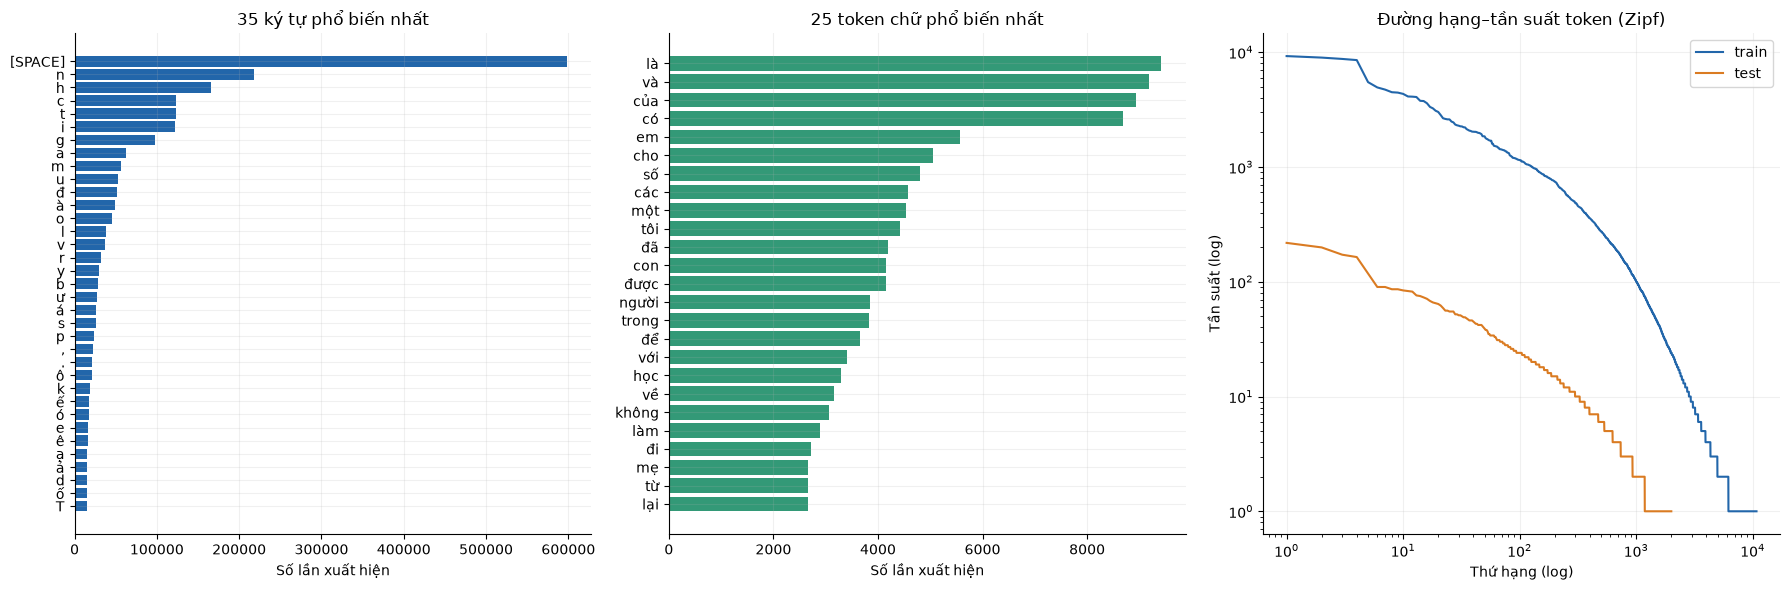

,character,train,test,total,display,codepoint,unicode_name,category
240,ᐟ,10,0,10,ᐟ,U+141F,CANADIAN SYLLABICS FINAL ACUTE,Lo
241,₫,10,0,10,₫,U+20AB,DONG SIGN,Sc
242,¹,10,0,10,¹,U+00B9,SUPERSCRIPT ONE,No
243,],10,0,10,],U+005D,RIGHT SQUARE BRACKET,Pe
244,Ẫ,10,0,10,Ẫ,U+1EAA,LATIN CAPITAL LETTER A WITH CIRCUMFLEX AND TILDE,Lu
245,@,9,0,9,@,U+0040,COMMERCIAL AT,Po
246,③,9,0,9,③,U+2462,CIRCLED DIGIT THREE,No
247,≥,9,0,9,≥,U+2265,GREATER-THAN OR EQUAL TO,Sm
248,ỵ,8,0,8,ỵ,U+1EF5,LATIN SMALL LETTER Y WITH DOT BELOW,Ll
249,√,7,1,8,√,U+221A,SQUARE ROOT,Sm


Có **404 loại ký tự NFC**, trong đó **164** loại xuất hiện ≤10 lần trên toàn bộ dữ liệu. Ngưỡng này chỉ phục vụ khám phá; vocab huấn luyện phải xây từ train.

In [7]:
char_counts = {s: Counter(''.join(df.loc[df.split.eq(s), 'text_nfc'])) for s in SPLITS}
token_counts = {s: Counter(t for text in df.loc[df.split.eq(s), 'text_nfc']
                           for t in re.findall(r'[^\W\d_]+', text.lower())) for s in SPLITS}
def counter_table(counters, key):
    keys = sorted(set().union(*(set(c) for c in counters.values())))
    out = pd.DataFrame({key: keys, **{s: [counters[s][k] for k in keys] for s in SPLITS}})
    out['total'] = out[SPLITS].sum(axis=1)
    return out.sort_values('total', ascending=False).reset_index(drop=True)
chars = counter_table(char_counts, 'character')
chars['display'] = chars.character.map(lambda c: {' ': '[SPACE]', '\n': r'\n', '\t': r'\t'}.get(c, c))
chars['codepoint'] = chars.character.map(lambda c: f'U+{ord(c):04X}')
chars['unicode_name'] = chars.character.map(lambda c: unicodedata.name(c, 'UNKNOWN'))
chars['category'] = chars.character.map(unicodedata.category)
tokens = counter_table(token_counts, 'token')
table(chars, 'character_frequencies', 35)
table(tokens, 'token_frequencies', 30)
lexical = []
for s in SPLITS:
    counts = np.array(list(char_counts[s].values()), dtype=float)
    p = counts / counts.sum() if counts.sum() else counts
    n_tok = sum(token_counts[s].values())
    lexical.append({'split': s, 'unique_characters': len(char_counts[s]),
                    'unique_tokens': len(token_counts[s]), 'token_occurrences': n_tok,
                    'token_type_ratio': len(token_counts[s]) / max(1, n_tok),
                    'hapax_token_types': sum(n == 1 for n in token_counts[s].values()),
                    'char_entropy_bits': float(-(p * np.log2(p)).sum())})
table(pd.DataFrame(lexical), 'lexical_diversity')
fig, axs = plt.subplots(1, 3, figsize=(18, 6))
top = chars.head(35).iloc[::-1]
axs[0].barh(top.display, top.total, color='#2266AA')
axs[0].set(title='35 ký tự phổ biến nhất', xlabel='Số lần xuất hiện')
top = tokens.head(25).iloc[::-1]
axs[1].barh(top.token, top.total, color='#339977')
axs[1].set(title='25 token chữ phổ biến nhất', xlabel='Số lần xuất hiện')
for s in SPLITS:
    freq = sorted(token_counts[s].values(), reverse=True)
    if freq:
        axs[2].loglog(np.arange(1, len(freq)+1), freq, label=s, color=COLORS.get(s))
axs[2].set(title='Đường hạng–tần suất token (Zipf)', xlabel='Thứ hạng (log)', ylabel='Tần suất (log)')
axs[2].legend()
finish(fig, '04_characters_tokens_zipf')
rare_chars = chars[chars.total.le(10)]
table(rare_chars, 'rare_characters', 50)
note(f'Có **{len(chars):,} loại ký tự NFC**, trong đó **{len(rare_chars):,}** loại xuất hiện ≤10 lần '
     'trên toàn bộ dữ liệu. Ngưỡng này chỉ phục vụ khám phá; vocab huấn luyện phải xây từ train.')

,split,tone,count
0,train,không dấu thanh,1565053
1,train,sắc,132816
2,train,nặng,93470
3,train,huyền,117393
4,train,hỏi,57412
5,train,ngã,27386
6,test,không dấu thanh,30922
7,test,huyền,2456
8,test,sắc,2705
9,test,hỏi,1295


,split,category,count
0,train,Dấu câu,73753
1,train,Số,28773
2,train,Khoảng cách,586252
3,train,Chữ cái,1993530
4,train,Ký hiệu,6415
5,train,Dấu kết hợp,29
6,train,Điều khiển/khác,15
7,test,Chữ cái,39845
8,test,Khoảng cách,11913
9,test,Dấu câu,1327


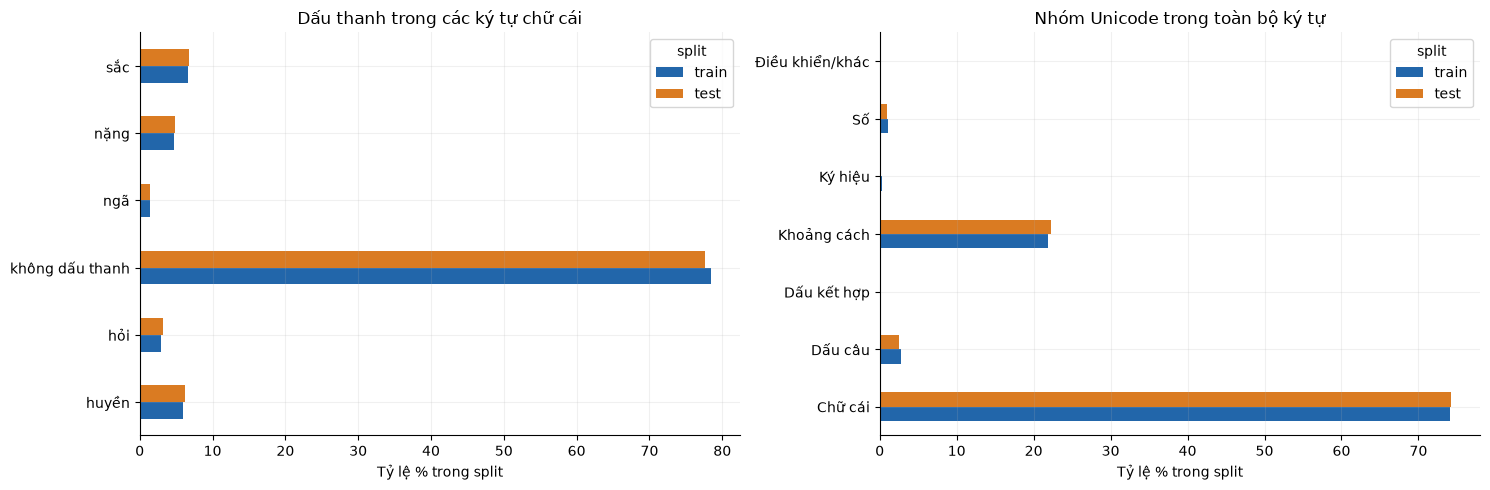

In [8]:
tone_rows, category_rows = [], []
for s in SPLITS:
    tones = Counter()
    categories = Counter()
    for ch, n in char_counts[s].items():
        if ch.isalpha():
            marks = [TONE_MARKS[m] for m in unicodedata.normalize('NFD', ch) if m in TONE_MARKS]
            tones.update({marks[0] if marks else 'không dấu thanh': n})
        cat = unicodedata.category(ch)[0]
        categories.update({{'L': 'Chữ cái', 'M': 'Dấu kết hợp', 'N': 'Số', 'P': 'Dấu câu',
                            'Z': 'Khoảng cách', 'S': 'Ký hiệu', 'C': 'Điều khiển/khác'}.get(cat, cat): n})
    tone_rows += [{'split': s, 'tone': k, 'count': v} for k, v in tones.items()]
    category_rows += [{'split': s, 'category': k, 'count': v} for k, v in categories.items()]
tone_df = pd.DataFrame(tone_rows, columns=['split', 'tone', 'count'])
category_df = pd.DataFrame(category_rows, columns=['split', 'category', 'count'])
table(tone_df, 'tone_frequencies')
table(category_df, 'unicode_category_frequencies')
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
for data, key, ax in [(tone_df, 'tone', axs[0]), (category_df, 'category', axs[1])]:
    if not data.empty:
        pivot = data.pivot_table(index=key, columns='split', values='count', fill_value=0).reindex(columns=SPLITS)
        pct = pivot.div(pivot.sum(axis=0).replace(0, np.nan), axis=1).mul(100)
        pct.plot.barh(ax=ax, color=[COLORS.get(s, '#777777') for s in SPLITS])
    ax.set(xlabel='Tỷ lệ % trong split', ylabel='')
axs[0].set_title('Dấu thanh trong các ký tự chữ cái')
axs[1].set_title('Nhóm Unicode trong toàn bộ ký tự')
finish(fig, '05_tones_unicode_categories')

## 6. Giải mã ảnh, hình học và các chỉ báo chất lượng

Mặc định quét **toàn bộ ảnh được tham chiếu bởi nhãn**: kiểm tra giải mã, kích thước gốc, mode, số byte, SHA-256 dữ liệu ảnh
mã hóa và SHA-256 pixel RGB (sau EXIF orientation, bao gồm kích thước).
Chỉ thumbnail giữ tỷ lệ tối đa 512×128 được dùng để tính độ sáng, tương phản, gradient và foreground
Otsu. Các đại lượng đó là **proxy**, không chứng minh độ mờ, lỗi nhãn hay chất lượng OCR.
dHash 64 bit chỉ dùng tìm ứng viên hình thái giống nhau; va chạm dHash không phải ảnh trùng.

Nếu đặt `IMAGE_LIMIT`, chỉ phần ảnh được chọn có thống kê ảnh/hash; nhãn vẫn phân tích đầy đủ.
`image_error` chỉ đếm mẫu đã thử đọc nhưng lỗi, không gộp mẫu chưa quét thành lỗi.

In [9]:
def otsu_threshold(arr):
    hist = np.bincount(arr.ravel(), minlength=256).astype(float)
    omega = np.cumsum(hist)
    mu = np.cumsum(hist * np.arange(256))
    denom = omega * (omega[-1] - omega)
    between = np.divide((mu[-1] * omega - mu * omega[-1])**2, denom,
                        out=np.zeros(256), where=denom > 0)
    return int(np.argmax(between))
def image_features(row):
    payload = get_image_bytes(row)
    with Image.open(io.BytesIO(payload)) as source:
        original_mode = source.mode
        rgb = ImageOps.exif_transpose(source).convert('RGB')
        rgb.load()  # Buộc giải mã toàn ảnh, không chỉ đọc header.
    w, h = rgb.size
    pixel_hasher = hashlib.sha256()
    pixel_hasher.update(f'RGB:{w}x{h}:'.encode())
    pixel_hasher.update(rgb.tobytes())
    grey = rgb.convert('L')
    tiny = np.asarray(grey.resize((9, 8), Image.Resampling.LANCZOS))
    dhash = np.packbits(tiny[:, 1:] > tiny[:, :-1]).tobytes().hex()
    grey.thumbnail(QUALITY_SIZE, Image.Resampling.LANCZOS)
    arr = np.asarray(grey)
    af = arr.astype(float)
    threshold = otsu_threshold(arr)
    mask = arr <= threshold if arr.std() > 0 else np.zeros_like(arr, dtype=bool)
    ys, xs = np.nonzero(mask)
    border = np.concatenate([mask[0], mask[-1], mask[:, 0], mask[:, -1]])
    bbox_ratio = ((xs.max()-xs.min()+1)*(ys.max()-ys.min()+1)/mask.size) if len(xs) else 0.
    dx = np.abs(np.diff(af, axis=1)).mean() if arr.shape[1] > 1 else 0.
    dy = np.abs(np.diff(af, axis=0)).mean() if arr.shape[0] > 1 else 0.
    return {'width': w, 'height': h, 'aspect_ratio': w/h, 'megapixels': w*h/1e6,
            'encoded_bytes': len(payload), 'image_mode': original_mode,
            'brightness': float(af.mean()), 'contrast': float(af.std()),
            'gradient_proxy': float((dx+dy)/2), 'foreground_ratio': float(mask.mean()),
            'border_ink_ratio': float(border.mean()), 'ink_bbox_ratio': bbox_ratio,
            'otsu_threshold': threshold, 'sha256_bytes': hashlib.sha256(payload).hexdigest(),
            'sha256_pixels': pixel_hasher.hexdigest(), 'dhash': dhash}
if IMAGE_LIMIT is None or IMAGE_LIMIT >= len(df):
    scan_index = df.index
else:
    if not isinstance(IMAGE_LIMIT, int) or IMAGE_LIMIT < len(SPLITS):
        raise ValueError('IMAGE_LIMIT phải là None hoặc số nguyên >= số split.')
    # Lấy mẫu ngẫu nhiên phân tầng gần tỷ lệ, đảm bảo mỗi split có ít nhất một ảnh.
    quota = df.groupby('split').size().reindex(SPLITS) / len(df) * IMAGE_LIMIT
    allocation = np.maximum(1, np.floor(quota).astype(int))
    allocation = np.minimum(allocation, df.groupby('split').size().reindex(SPLITS))
    while allocation.sum() > IMAGE_LIMIT:
        k = (allocation - quota).where(allocation > 1, -np.inf).idxmax()
        allocation[k] -= 1
    while allocation.sum() < IMAGE_LIMIT:
        available = df.groupby('split').size().reindex(SPLITS) > allocation
        k = (quota - allocation).where(available, -np.inf).idxmax()
        allocation[k] += 1
    scan_index = pd.Index([i for s in SPLITS for i in df[df.split.eq(s)].sample(
        n=int(allocation[s]), random_state=SEED).index])
img_records = []
for row in tqdm(df.loc[scan_index].itertuples(), total=len(scan_index), desc='Giải mã và thống kê ảnh'):
    result = {'sample_id': row.sample_id, 'image_scanned': True, 'image_error': ''}
    try:
        result.update(image_features(row))
    except Exception as exc:
        result['image_error'] = f'{type(exc).__name__}: {exc}'[:500]
    img_records.append(result)
df = df.merge(pd.DataFrame(img_records), on='sample_id', how='left', validate='one_to_one')
df['image_scanned'] = df.image_scanned.eq(True)
df['image_error'] = df.image_error.fillna('')
if 'width' not in df or df.width.notna().sum() == 0:
    raise RuntimeError('Không ảnh nào đọc thành công. Xem img_records để chẩn đoán.')
df['image_ok'] = df.image_scanned & df.image_error.eq('') & df.width.notna()
valid = df[df.image_ok].copy()
valid['chars_per_100px'] = valid.n_chars / valid.width * 100
coverage = df.groupby('split').agg(n_labels=('sample_id', 'size'),
    n_scanned=('image_scanned', 'sum'), n_decoded=('image_ok', 'sum'))
coverage['n_image_errors'] = coverage.n_scanned - coverage.n_decoded
coverage['scan_percent'] = 100 * coverage.n_scanned / coverage.n_labels
table(coverage.reset_index(), 'image_coverage')
table(df[df.image_scanned & ~df.image_ok][['sample_id', 'split', 'image_error']], 'image_errors')
note(f'Đã giải mã thành công **{len(valid):,}/{len(scan_index):,} ảnh đã quét**; '
     f'độ phủ **{100*len(scan_index)/len(df):.2f}%** tổng nhãn. '
     'Các kết quả ảnh bên dưới chỉ dùng ảnh giải mã thành công.')

Giải mã và thống kê ảnh:   0%|          | 0/60247 [00:00<?, ?it/s]

Giải mã và thống kê ảnh:   0%|          | 60/60247 [00:00<01:41, 591.05it/s]

Giải mã và thống kê ảnh:   0%|          | 126/60247 [00:00<01:35, 629.46it/s]

Giải mã và thống kê ảnh:   0%|          | 189/60247 [00:00<01:36, 619.27it/s]

Giải mã và thống kê ảnh:   0%|          | 251/60247 [00:00<01:40, 595.98it/s]

...

Giải mã và thống kê ảnh: 100%|█████████▉| 60240/60247 [01:49<00:00, 489.14it/s]

Giải mã và thống kê ảnh: 100%|██████████| 60247/60247 [01:49<00:00, 552.53it/s]

,split,n_labels,n_scanned,n_decoded,n_image_errors,scan_percent
0,test,1000,1000,1000,0,100.0
1,train,59247,59247,59247,0,100.0


,sample_id,split,image_error


Đã giải mã thành công **60,247/60,247 ảnh đã quét**; độ phủ **100.00%** tổng nhãn. Các kết quả ảnh bên dưới chỉ dùng ảnh giải mã thành công.

,split,metric,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
0,test,width,1000.0,764.944000,393.542901,104.000000,178.930000,296.900000,504.750000,701.000000,918.250000,1534.300000,2148.050000,3.342000e+03
1,test,height,1000.0,61.339000,35.151525,15.000000,20.000000,25.000000,39.000000,55.000000,73.000000,121.100000,204.100000,3.520000e+02
2,test,aspect_ratio,1000.0,13.176049,4.113963,3.307692,4.707144,7.113612,10.781359,12.684962,14.927995,20.544598,27.471744,3.178846e+01
3,test,encoded_bytes,1000.0,20596.505000,20981.728366,1745.000000,3056.400000,4975.450000,9648.750000,15165.500000,24076.000000,52663.100000,105822.810000,2.528680e+05
4,test,brightness,1000.0,173.243815,32.158198,62.508475,98.140612,122.430180,150.944251,171.107619,194.812613,230.284357,242.012141,2.477479e+02
5,test,contrast,1000.0,30.595676,10.431243,7.708506,12.408499,16.761388,23.319981,29.120771,36.355287,49.909391,60.399546,8.427539e+01
6,test,gradient_proxy,1000.0,10.632458,4.470899,1.951257,3.330474,4.758229,7.355833,9.892677,13.207546,19.090195,23.419429,2.903856e+01
7,test,foreground_ratio,1000.0,0.193263,0.123752,0.014812,0.073323,0.094575,0.128015,0.158804,0.201470,0.449985,0.797049,9.139441e-01
8,test,border_ink_ratio,1000.0,0.148306,0.163851,0.000000,0.000000,0.002701,0.036202,0.089652,0.201979,0.474898,0.867292,1.000000e+00
9,test,ink_bbox_ratio,1000.0,0.960192,0.082152,0.413326,0.589547,0.773121,0.975588,0.988281,0.997746,1.000000,1.000000,1.000000e+00


,split,image_mode,count
0,test,RGB,1000
1,train,RGB,59247


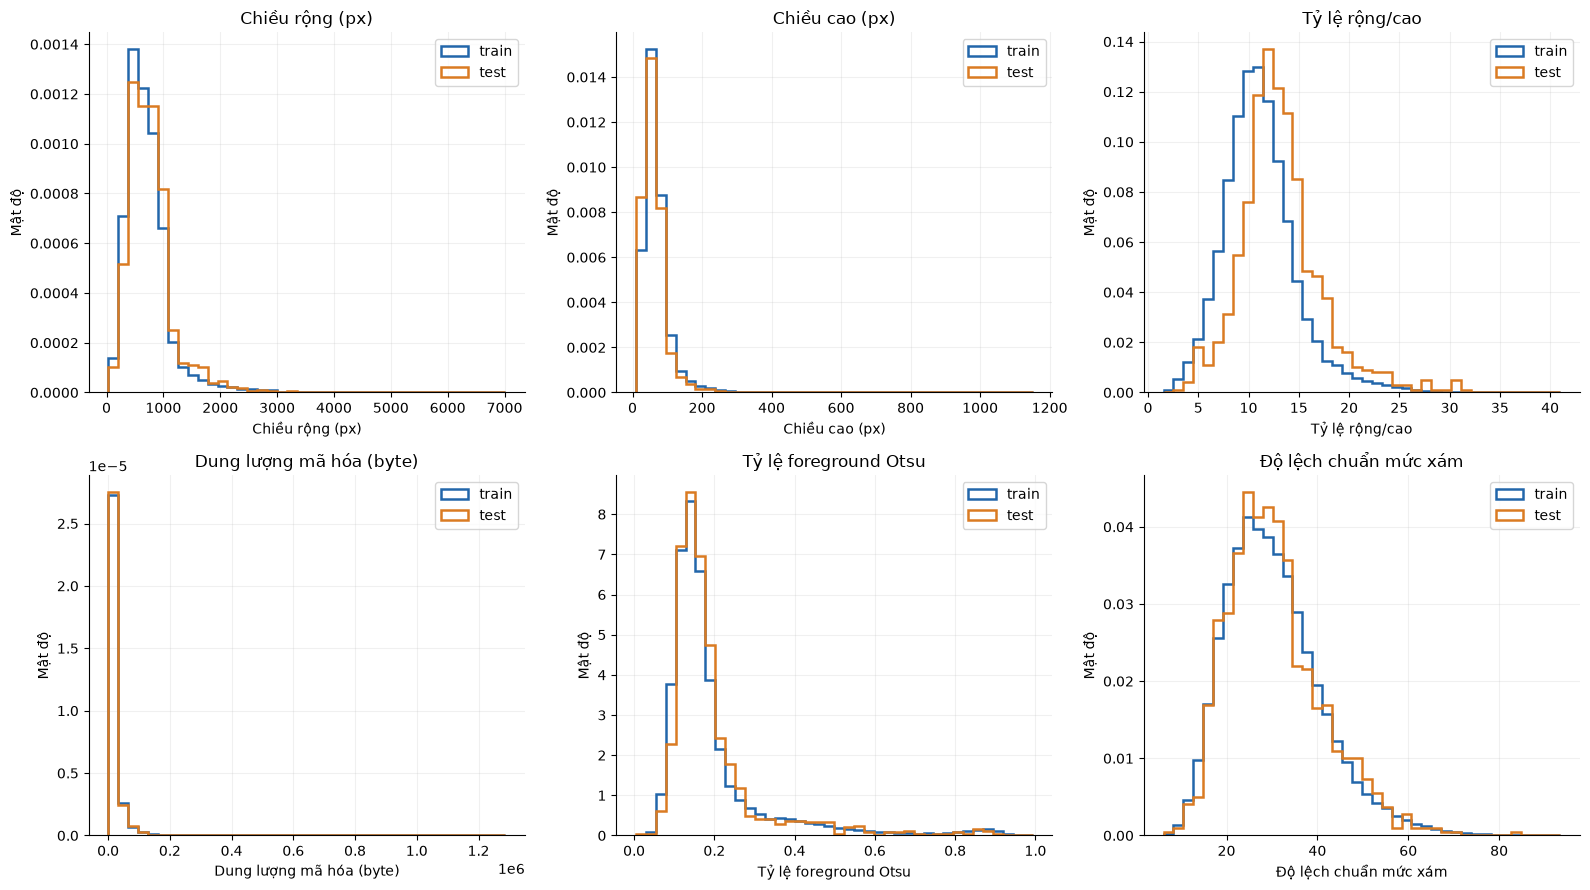

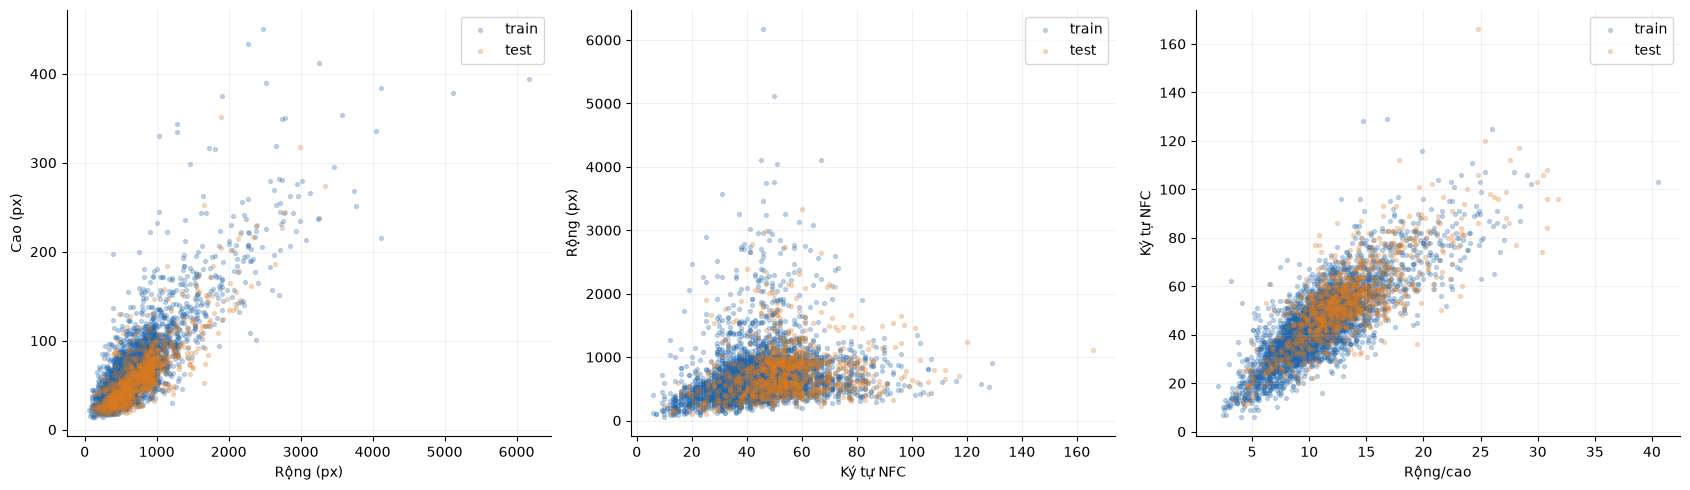

,feature,n_chars,n_tokens_ws,width,height,aspect_ratio,foreground_ratio,contrast,gradient_proxy
0,n_chars,1.000000,0.956550,0.366152,-0.137725,0.783472,0.146326,0.072220,0.228726
1,n_tokens_ws,0.956550,1.000000,0.366765,-0.124185,0.763138,0.129055,0.057964,0.205821
2,width,0.366152,0.366765,1.000000,0.755509,0.360017,-0.093032,0.023736,-0.039864
3,height,-0.137725,-0.124185,0.755509,1.000000,-0.266869,-0.187445,-0.044334,-0.230068
4,aspect_ratio,0.783472,0.763138,0.360017,-0.266869,1.000000,0.116286,0.084031,0.235585
5,foreground_ratio,0.146326,0.129055,-0.093032,-0.187445,0.116286,1.000000,0.130116,0.072703
6,contrast,0.072220,0.057964,0.023736,-0.044334,0.084031,0.130116,1.000000,0.793915
7,gradient_proxy,0.228726,0.205821,-0.039864,-0.230068,0.235585,0.072703,0.793915,1.000000


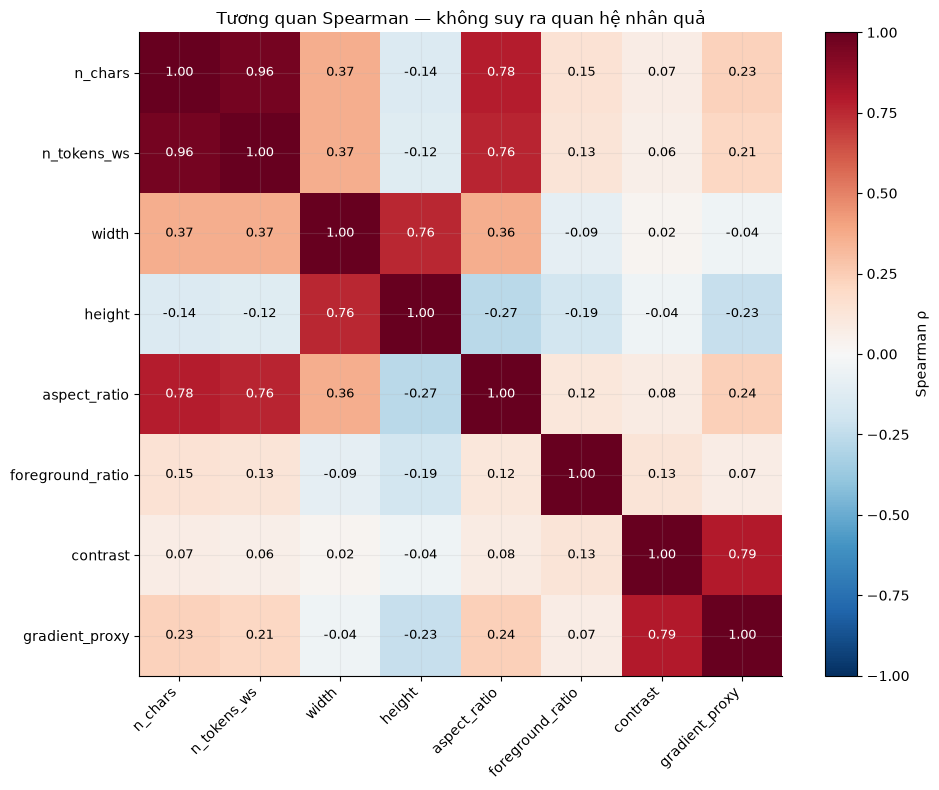

In [10]:
IMAGE_METRICS = ['width', 'height', 'aspect_ratio', 'encoded_bytes', 'brightness',
                 'contrast', 'gradient_proxy', 'foreground_ratio', 'border_ink_ratio', 'ink_bbox_ratio']
image_desc = valid.groupby('split')[IMAGE_METRICS].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99])
table(image_desc.stack(level=0, future_stack=True).rename_axis(['split', 'metric']).reset_index(),
      'image_descriptive_statistics', 40)
table(valid.groupby(['split', 'image_mode']).size().rename('count').reset_index(), 'image_modes')
fig, axs = plt.subplots(2, 3, figsize=(16, 9))
for ax, col, label in zip(axs.ravel(), ['width', 'height', 'aspect_ratio', 'encoded_bytes',
                                       'foreground_ratio', 'contrast'],
                        ['Chiều rộng (px)', 'Chiều cao (px)', 'Tỷ lệ rộng/cao',
                         'Dung lượng mã hóa (byte)', 'Tỷ lệ foreground Otsu', 'Độ lệch chuẩn mức xám']):
    bins = np.histogram_bin_edges(valid[col], bins=40)
    for s in SPLITS:
        vals = valid.loc[valid.split.eq(s), col]
        if len(vals):
            ax.hist(vals, bins=bins, density=True, histtype='step', linewidth=1.8,
                    label=s, color=COLORS.get(s))
    ax.set(xlabel=label, ylabel='Mật độ', title=label)
    ax.legend()
finish(fig, '06_image_distributions')
fig, axs = plt.subplots(1, 3, figsize=(17, 5))
for s in SPLITS:
    plot_data = valid[valid.split.eq(s)].sample(min(4000, sum(valid.split.eq(s))), random_state=SEED)
    axs[0].scatter(plot_data.width, plot_data.height, s=8, alpha=.25, color=COLORS.get(s), label=s)
    axs[1].scatter(plot_data.n_chars, plot_data.width, s=8, alpha=.25, color=COLORS.get(s), label=s)
    axs[2].scatter(plot_data.aspect_ratio, plot_data.n_chars, s=8, alpha=.25, color=COLORS.get(s), label=s)
for ax, x, y in [(axs[0], 'Rộng (px)', 'Cao (px)'), (axs[1], 'Ký tự NFC', 'Rộng (px)'),
                 (axs[2], 'Rộng/cao', 'Ký tự NFC')]:
    ax.set(xlabel=x, ylabel=y); ax.legend()
finish(fig, '07_image_geometry_text_relations')
corr_cols = ['n_chars', 'n_tokens_ws', 'width', 'height', 'aspect_ratio',
             'foreground_ratio', 'contrast', 'gradient_proxy']
corr = valid[corr_cols].corr(method='spearman')
table(corr.rename_axis('feature').reset_index(), 'spearman_correlations')
fig, ax = plt.subplots(figsize=(10, 8))
heat = ax.imshow(corr, vmin=-1, vmax=1, cmap='RdBu_r')
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha='right')
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        value = corr.iloc[i, j]
        ax.text(j, i, f'{value:.2f}', ha='center', va='center',
                color='white' if abs(value) > .65 else 'black', fontsize=9)
ax.set_title('Tương quan Spearman — không suy ra quan hệ nhân quả')
fig.colorbar(heat, ax=ax, label='Spearman ρ')
finish(fig, '08_correlation_heatmap')

## 7. Ảnh minh họa ngẫu nhiên và những trường hợp cần xem xét

Các gallery kèm mã mẫu, split, kích thước và nhãn xuống dòng để đối chiếu trực quan.
Mỗi split lấy tối đa bốn ảnh ngẫu nhiên; các gallery còn lại chọn theo tiêu chí cụ thể.
Ngưỡng tương phản/foreground/chạm biên ở dưới chỉ để lập danh sách kiểm tra, không tự loại ảnh.
Trắng/đen bị đảo hoặc nền có hoa văn có thể làm Otsu cho kết quả không phù hợp.

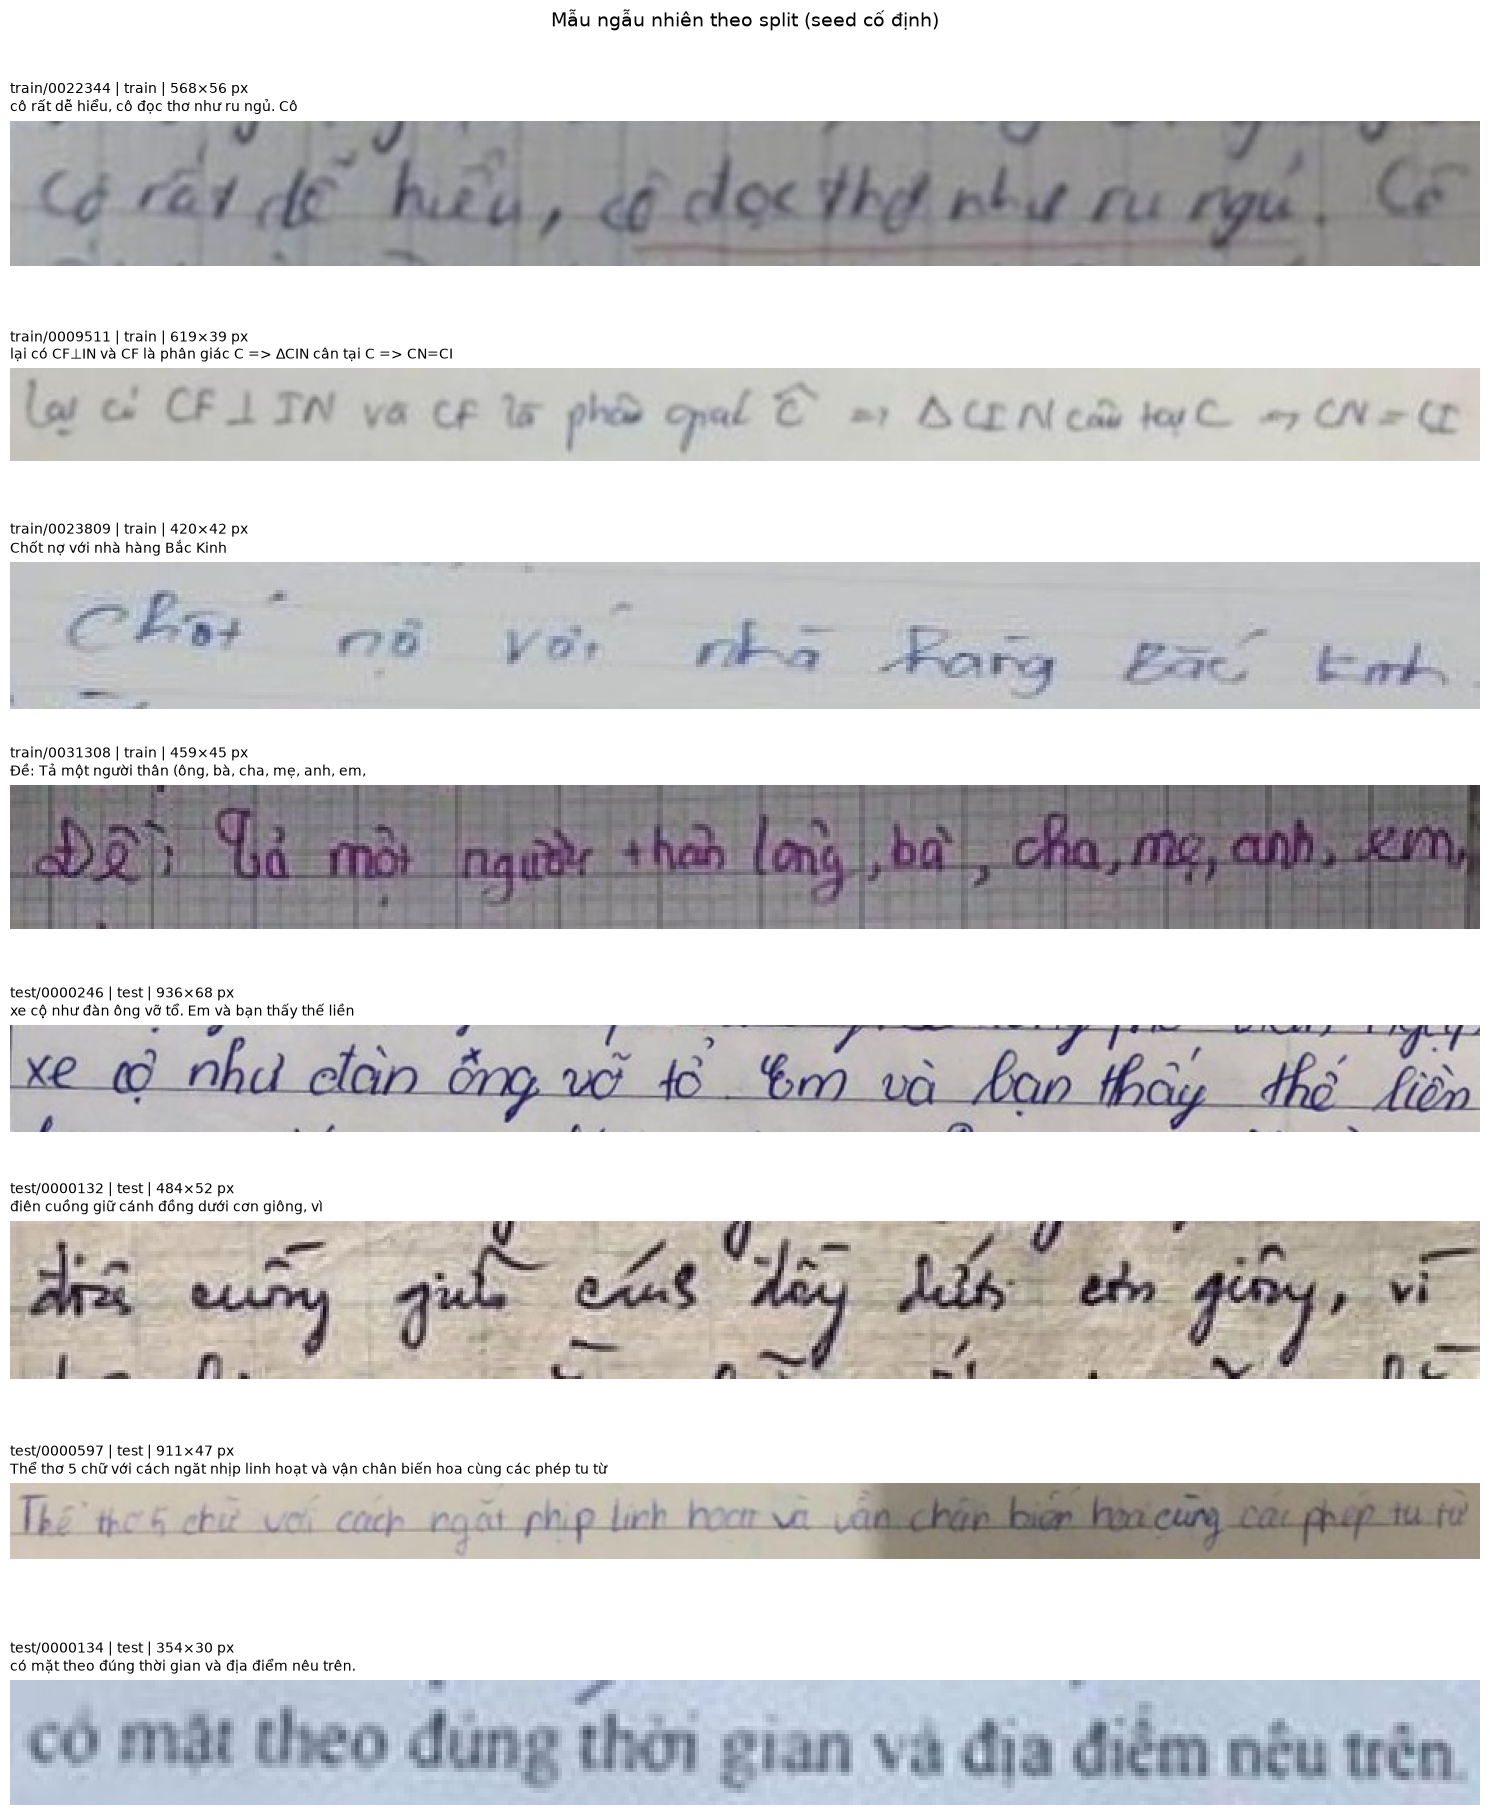

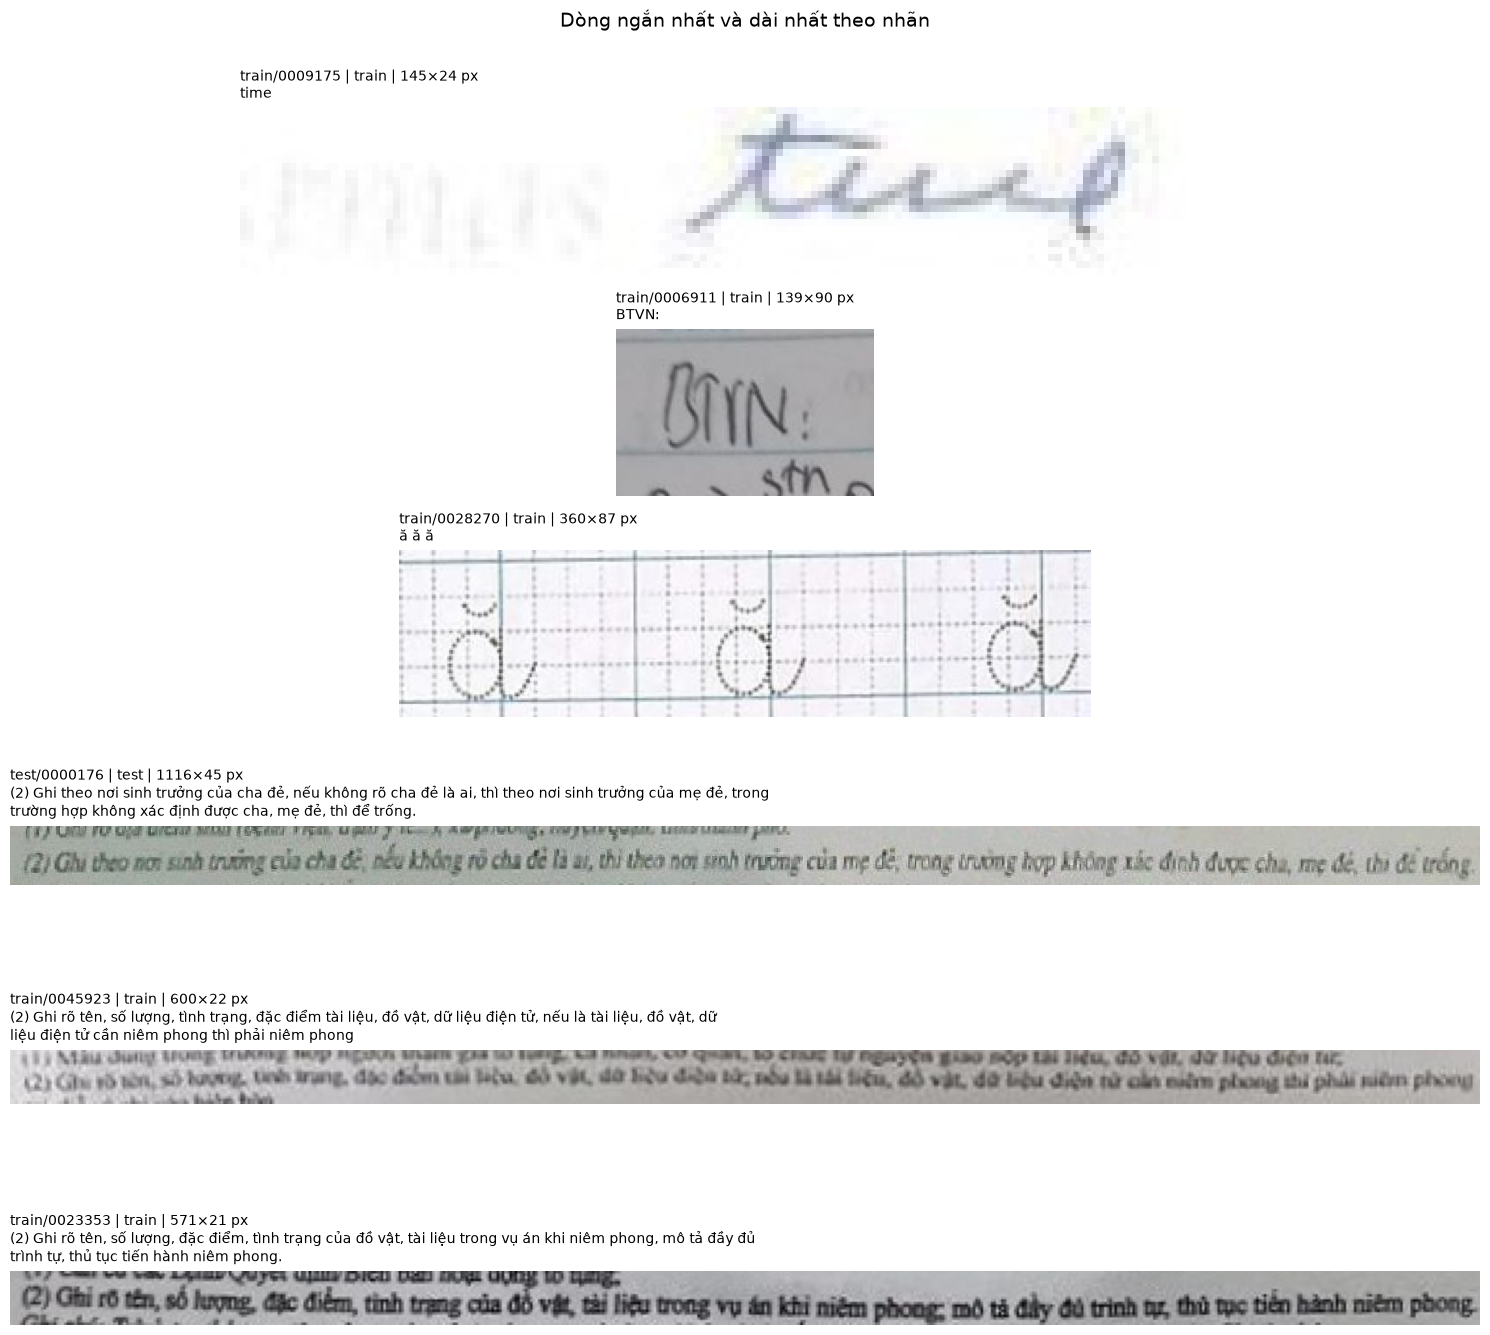

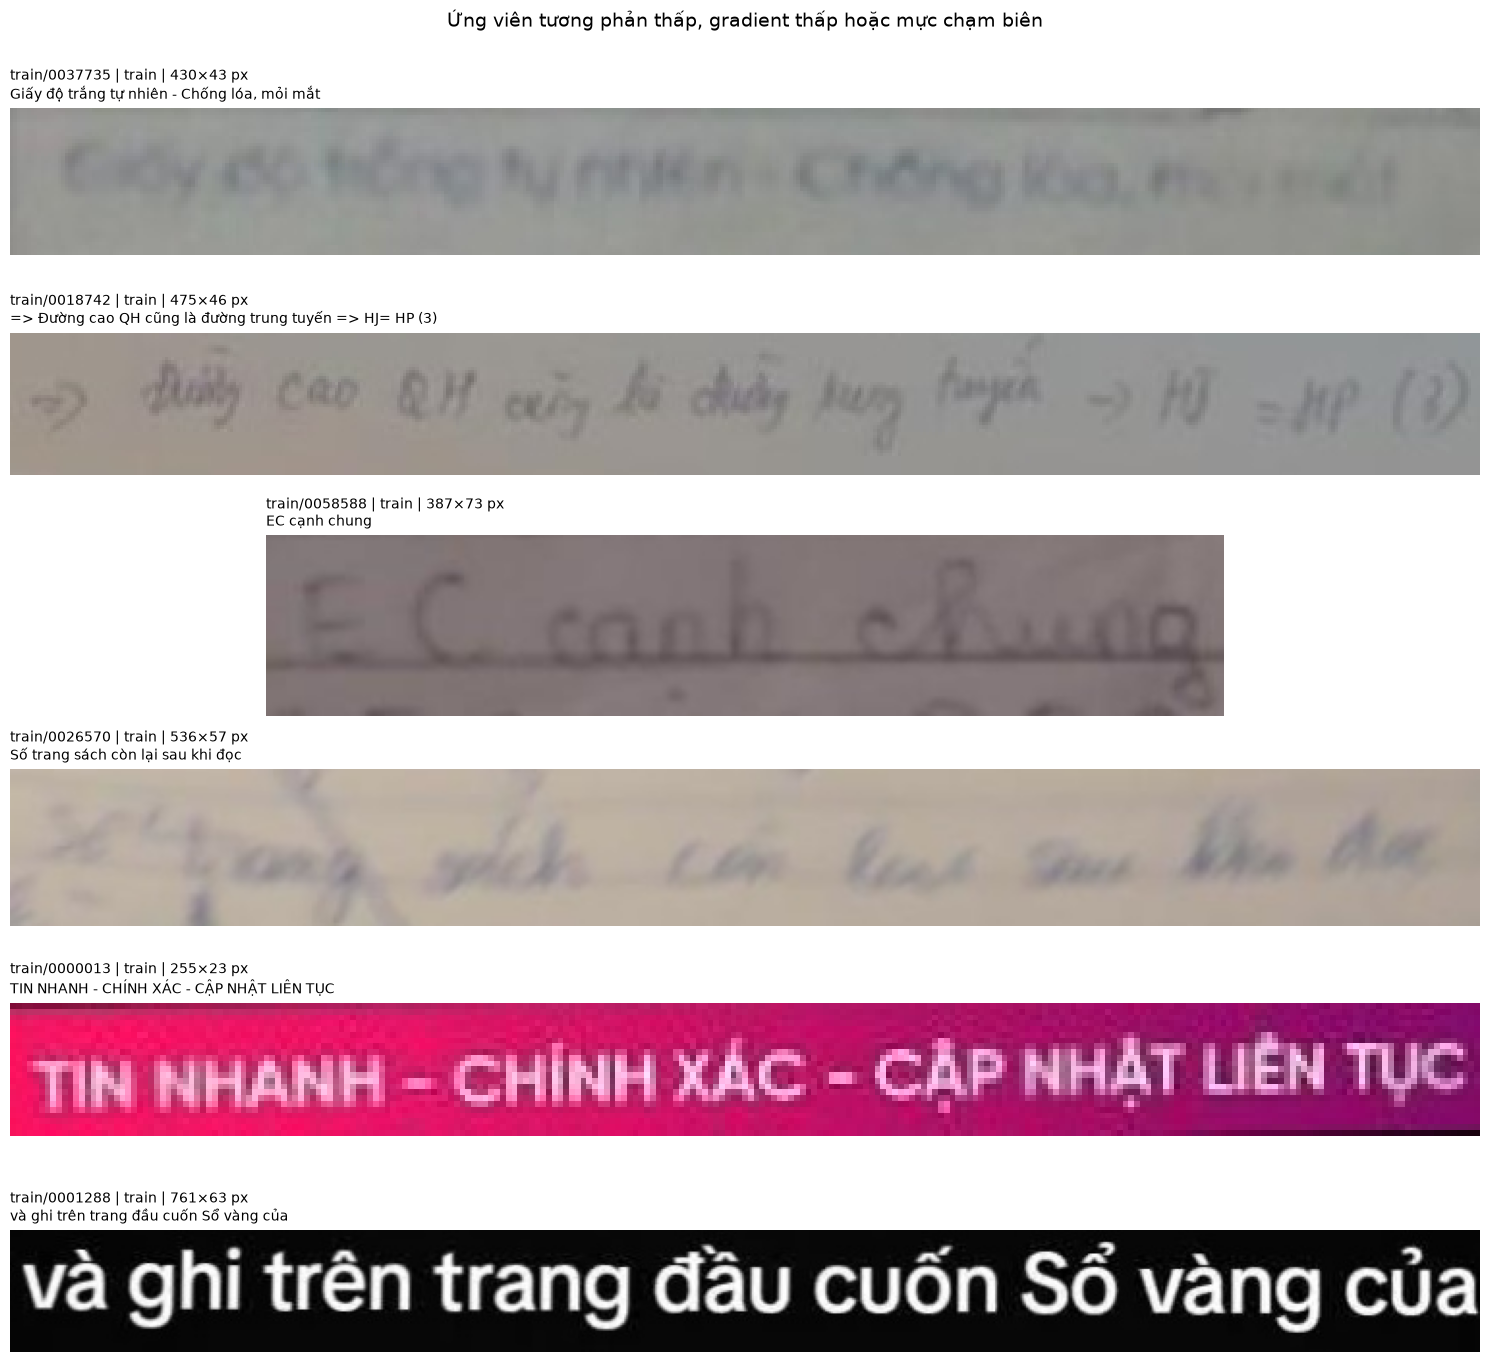

split,flag,test,train
0,flag_low_contrast,0.3,0.214357
1,flag_sparse_ink,0.0,0.001688
2,flag_dense_ink,1.4,2.133441
3,flag_border_ink,25.2,27.029217
4,flag_tiny_height,0.1,0.114774


,sample_id,split,text_nfc,width,height,aspect_ratio,encoded_bytes,brightness,contrast,gradient_proxy,foreground_ratio,border_ink_ratio,ink_bbox_ratio,flag_low_contrast,flag_sparse_ink,flag_dense_ink,flag_border_ink,flag_tiny_height
1,train/0000001,train,Ngôi nhà chung 2C,381,99,3.848485,23006,86.011347,34.679765,12.271195,0.803362,0.834375,1.000000,False,False,True,True,False
4,train/0000004,train,tháng 4- 2023: hiện nay sức khoẻ của tôi,759,66,11.500000,25500,171.430686,48.266638,17.333324,0.165321,0.210952,0.996094,False,False,False,True,False
8,train/0000008,train,cần xáo trộn vị trí sẽ được 1 kiểu sắp xếp,871,90,9.677778,19482,187.748858,30.043695,4.208067,0.437979,0.380531,0.994141,False,False,False,True,False
9,train/0000009,train,nghi ngút chính là báo hiệu cho sự ầm áp của gđ.,924,67,13.791045,18172,179.121094,13.446721,5.120017,0.164590,0.229508,0.992188,False,False,False,True,False
11,train/0000011,train,cho đi là còn mãi. Hãy biết lan tỏa yêu,910,69,13.188406,23251,217.486829,29.690279,7.995919,0.197766,0.285844,0.982422,False,False,False,True,False
12,train/0000012,train,a Tổng số sản phẩm của xưởng đó là:,564,65,8.676923,14400,109.875033,17.343049,5.840703,0.207958,0.288091,1.000000,False,False,False,True,False
13,train/0000013,train,TIN NHANH - CHÍNH XÁC - CẬP NHẬT LIÊN TỤC,255,23,11.086957,4805,98.542029,41.407842,16.054006,0.826087,1.000000,1.000000,False,False,True,True,False
18,train/0000018,train,Mẹ thích nấu ăn và chơi tennis. Chị em học,611,68,8.985294,20358,170.705387,38.188696,12.176338,0.141173,0.272408,1.000000,False,False,False,True,False
20,train/0000020,train,1) Vũ Nương khi ở trần gian.,453,66,6.863636,9745,123.678139,24.991183,5.287535,0.895545,0.996146,1.000000,False,False,True,True,False
22,train/0000022,train,"Đồng A II sẽ vẫn được tổ chức sinh nhật, để ch...",259,18,14.388889,4229,153.495495,34.775086,16.862479,0.201845,0.218412,0.984556,False,False,False,True,False


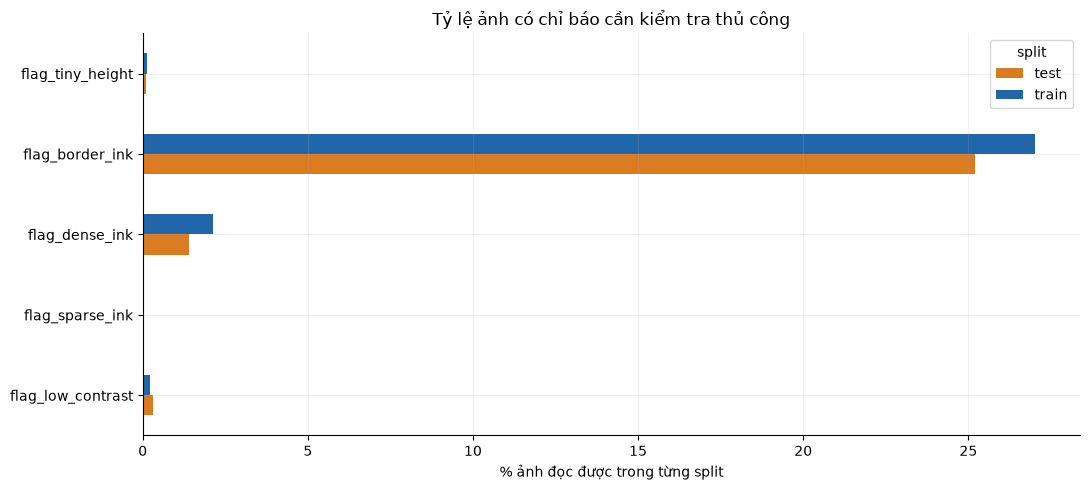

In [11]:
import textwrap
def gallery(rows, title, name, max_items=8):
    rows = rows.head(max_items)
    if rows.empty:
        note(f'{title}: không có mẫu phù hợp.'); return
    fig, axs = plt.subplots(len(rows), 1, figsize=(15, 2.3 * len(rows)), squeeze=False)
    for ax, row in zip(axs.ravel(), rows.itertuples()):
        with Image.open(io.BytesIO(get_image_bytes(row))) as im:
            ax.imshow(ImageOps.exif_transpose(im).convert('RGB'))
        ax.axis('off')
        label = textwrap.fill(row.text_nfc, width=112)
        ax.set_title(f'{row.sample_id} | {row.split} | {int(row.width)}×{int(row.height)} px\n{label}',
                     loc='left', fontsize=10, pad=7)
    fig.suptitle(title, fontsize=14, y=1.005)
    finish(fig, name)
random_rows = pd.concat([valid[valid.split.eq(s)].sample(min(4, sum(valid.split.eq(s))),
                         random_state=SEED) for s in SPLITS])
gallery(random_rows, 'Mẫu ngẫu nhiên theo split (seed cố định)', '09_random_gallery', max_items=12)
gallery(pd.concat([valid.nsmallest(3, 'n_chars'), valid.nlargest(3, 'n_chars')]).drop_duplicates('sample_id'),
        'Dòng ngắn nhất và dài nhất theo nhãn', '10_extreme_lengths_gallery')
gallery(pd.concat([valid.nsmallest(2, 'contrast'), valid.nsmallest(2, 'gradient_proxy'),
                   valid.nlargest(2, 'border_ink_ratio')]).drop_duplicates('sample_id'),
        'Ứng viên tương phản thấp, gradient thấp hoặc mực chạm biên', '11_quality_gallery')
valid['flag_low_contrast'] = valid.contrast.lt(10)
valid['flag_sparse_ink'] = valid.foreground_ratio.lt(.005)
valid['flag_dense_ink'] = valid.foreground_ratio.gt(.70)
valid['flag_border_ink'] = valid.border_ink_ratio.gt(.20)
valid['flag_tiny_height'] = valid.height.lt(16)
image_flags = [c for c in valid if c.startswith('flag_')]
flag_rates = valid.groupby('split')[image_flags].mean().mul(100).T
table(flag_rates.rename_axis('flag').reset_index(), 'image_flag_percentages')
table(valid[valid[image_flags].any(axis=1)][['sample_id', 'split', 'text_nfc'] + IMAGE_METRICS + image_flags],
      'images_for_manual_review', 20)
fig, ax = plt.subplots(figsize=(11, 5))
flag_rates.plot.barh(ax=ax, color=[COLORS.get(s, '#777777') for s in flag_rates.columns])
ax.set(title='Tỷ lệ ảnh có chỉ báo cần kiểm tra thủ công', xlabel='% ảnh đọc được trong từng split', ylabel='')
finish(fig, '12_image_quality_flags')

## 8. Trùng lặp, nhãn xung đột và giao giữa train/test

Phân biệt: **cùng nhãn** có thể là nhiều người viết cùng một nội dung;
**cùng byte** là tệp ảnh mã hóa giống hệt; **cùng pixel RGB và kích thước** là cùng nội dung ảnh
sau chuẩn hóa orientation/mode, bỏ qua metadata. Cùng ảnh nằm ở hai split là rủi ro rò rỉ trực tiếp.
Cùng nhãn giữa split cho thấy nội dung đã gặp, chưa đủ kết luận rò rỉ ảnh/người viết.
Hash giống nhưng nhãn khác được xuất để rà soát. dHash giống chỉ là ứng viên, đặc biệt với ảnh dài.

,sample_id,split,text_compare,text_nfc
6493,train/0006493,train,"""Cuộc sống hằng ngày của em áp lực lắm nó như","""Cuộc sống hằng ngày của em áp lực lắm nó như"
54536,train/0054536,train,"""Cuộc sống hằng ngày của em áp lực lắm nó như","""Cuộc sống hằng ngày của em áp lực lắm nó như"
1701,train/0001701,train,"""Cô lo mà học hành đi, trứng chưa tới","""Cô lo mà học hành đi, trứng chưa tới"
21426,train/0021426,train,"""Cô lo mà học hành đi, trứng chưa tới","""Cô lo mà học hành đi, trứng chưa tới"
14500,train/0014500,train,"""Dành tặng những tình cảm sâu sắc và tôn kính ...","""Dành tặng những tình cảm sâu sắc và tôn kính ..."
17791,train/0017791,train,"""Dành tặng những tình cảm sâu sắc và tôn kính ...","""Dành tặng những tình cảm sâu sắc và tôn kính ..."
50681,train/0050681,train,"""Dành tặng những tình cảm sâu sắc và tôn kính ...","""Dành tặng những tình cảm sâu sắc và tôn kính ..."
10055,train/0010055,train,"""Nhảy qua đèo ngang nhớ lấy đà""","""Nhảy qua đèo ngang nhớ lấy đà"""
13637,train/0013637,train,"""Nhảy qua đèo ngang nhớ lấy đà""","""Nhảy qua đèo ngang nhớ lấy đà"""
30399,train/0030399,train,"""Nhảy qua đèo ngang nhớ lấy đà""","""Nhảy qua đèo ngang nhớ lấy đà"""


,sample_id,split,sha256_bytes,text_nfc


,sample_id,split,sha256_pixels,text_nfc


,sample_id,split,dhash,text_nfc
59496,test/0000249,test,0000000000000000,thực tế về một di tích lịch sử gắn liền với qu...
59734,test/0000487,test,0000000000000000,cảm ơn ông bà vì món quà sinh nhật tuyệt vời n...
953,train/0000953,train,0000000000000000,Cho KG của hoa đỏ lai với KG đồng hợp lặn aa (...
1846,train/0001846,train,0000000000000000,"cửa kính, ô tô, cảm giác, thác, mây trời, rừng,"
2980,train/0002980,train,0000000000000000,"vài dòng đã ngáp ngắn ngáp dài, rồi bỏ dở. Nhữ..."
3150,train/0003150,train,0000000000000000,suy nghĩ hết sức giản dị mà sâu sắc
7015,train/0007015,train,0000000000000000,"Đôi môi cô đỏ hồng, khi nụ cười ấy nở ra thì"
7999,train/0007999,train,0000000000000000,"rất yêu nhân dân và tổ quốc, lo cho vận mệnh"
8588,train/0008588,train,0000000000000000,"b) Em hiểu ntn về câu nói ""Có người thường trú..."
9137,train/0009137,train,0000000000000000,các phương pháp lập luận khác nhau như


,key,scope_n,duplicate_groups,samples_in_groups,redundant_copies,cross_split_groups,conflicting_label_groups
0,text_compare,60247,4022,11597,7575,171,0
1,sha256_bytes,60247,0,0,0,0,0
2,sha256_pixels,60247,0,0,0,0,0
3,dhash,60247,224,731,507,9,145


,split,train,test
0,train,51846,171
1,test,171,997


,split,train,test
0,train,59247,0
1,test,0,1000


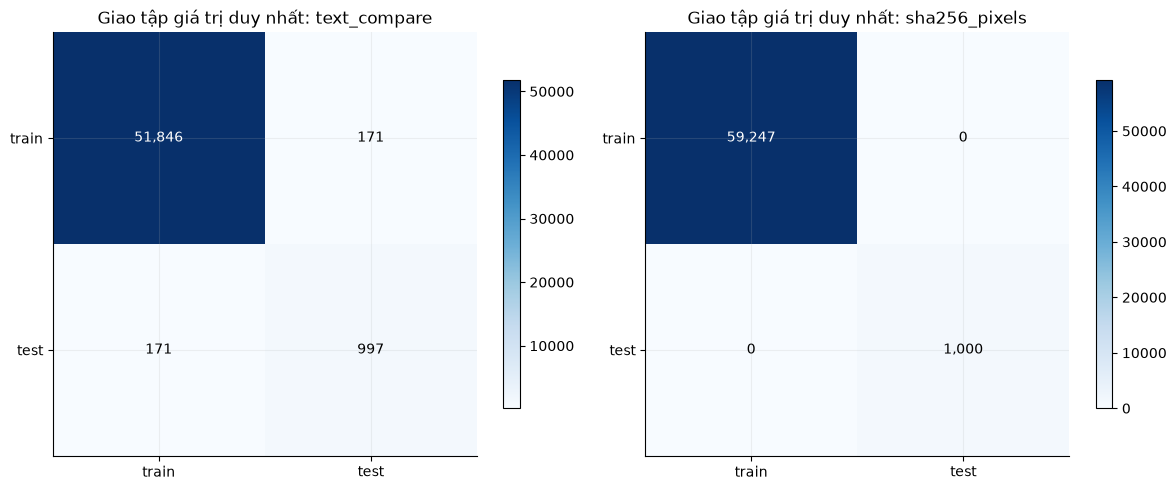

,sample_id,split,sha256_pixels,text_raw,text_compare


Ví dụ cùng pixel ảnh xuất hiện ở nhiều split: không có mẫu phù hợp.

In [12]:
duplicate_rows = []
for key, frame in [('text_compare', df[df.text_compare.ne('')]),
                   ('sha256_bytes', valid), ('sha256_pixels', valid), ('dhash', valid)]:
    group = frame.groupby(key).agg(n=('sample_id', 'size'), n_splits=('split', 'nunique'),
                                  n_labels=('text_compare', 'nunique'))
    dup = group[group.n.gt(1)]
    duplicate_rows.append({'key': key, 'scope_n': len(frame), 'duplicate_groups': len(dup),
                           'samples_in_groups': int(dup.n.sum()),
                           'redundant_copies': int((dup.n-1).sum()),
                           'cross_split_groups': int(dup.n_splits.gt(1).sum()),
                           'conflicting_label_groups': int(dup.n_labels.gt(1).sum())})
    matches = frame[frame[key].isin(dup.index)].sort_values([key, 'split'])
    table(matches[['sample_id', 'split', key, 'text_nfc']], f'duplicate_{key}', 10)
duplicates = pd.DataFrame(duplicate_rows)
table(duplicates, 'duplicate_summary')
cross_rows = []
for key, frame in [('text_compare', df[df.text_compare.ne('')]), ('sha256_pixels', valid)]:
    matrix = pd.DataFrame(0, index=SPLITS, columns=SPLITS, dtype=int)
    sets = {s: set(frame.loc[frame.split.eq(s), key].dropna()) for s in SPLITS}
    for a in SPLITS:
        for b in SPLITS:
            matrix.loc[a, b] = len(sets[a] & sets[b])
    cross_rows.append((key, matrix))
    table(matrix.rename_axis('split').reset_index(), f'cross_split_{key}')
fig, axs = plt.subplots(1, 2, figsize=(12, 5))
for ax, (key, matrix) in zip(axs, cross_rows):
    heat = ax.imshow(matrix, cmap='Blues')
    for i in range(len(SPLITS)):
        for j in range(len(SPLITS)):
            ax.text(j, i, f'{matrix.iloc[i,j]:,}', ha='center', va='center',
                    color='white' if matrix.iloc[i,j] > matrix.to_numpy().max()/2 else 'black')
    ax.set_xticks(range(len(SPLITS)), SPLITS); ax.set_yticks(range(len(SPLITS)), SPLITS)
    ax.set_title(f'Giao tập giá trị duy nhất: {key}')
    fig.colorbar(heat, ax=ax, shrink=.7)
finish(fig, '13_cross_split_overlap')
pixel_groups = valid.groupby('sha256_pixels').agg(n=('sample_id', 'size'),
                  n_splits=('split', 'nunique'), n_labels=('text_compare', 'nunique'))
conflict_hashes = pixel_groups.index[pixel_groups.n_labels.gt(1)]
cross_hashes = pixel_groups.index[pixel_groups.n_splits.gt(1)]
table(valid[valid.sha256_pixels.isin(conflict_hashes)][
    ['sample_id', 'split', 'sha256_pixels', 'text_raw', 'text_compare']], 'pixel_label_conflicts')
cross_image_examples = valid[valid.sha256_pixels.isin(cross_hashes)].sort_values('sha256_pixels')
gallery(cross_image_examples, 'Ví dụ cùng pixel ảnh xuất hiện ở nhiều split', '14_cross_split_gallery', 6)

## 9. Độ khác biệt giữa train/test và khả năng bao phủ của train

Đo OOV ký tự và token trên từng split còn lại bằng vocab **chỉ từ train**.
Báo cáo theo loại, theo lượt xuất hiện và tỷ lệ dòng có ít nhất một OOV.
Jensen–Shannon distance dùng log cơ số 2 (0 đến 1): đo khác biệt phân phối ký tự.
KS statistic đo khoảng cách ECDF; p-value chỉ tham khảo vì ảnh/nhãn có thể phụ thuộc theo trang,
người viết và nội dung lặp. Không diễn giải p nhỏ là mức khác biệt thực tế lớn.

Jensen–Shannon distance ký tự **train ↔ test: 0.0538**.

,split,unseen_char_types,char_oov_occurrences,char_oov_percent,lines_with_char_oov_percent,unseen_token_types,token_oov_percent,lines_with_token_oov_percent
0,test,0,0,0.0,0.0,71,0.564119,6.3


,split,character,codepoint,count


,split_vs_train,metric,n_train,n_other,median_train,median_other,median_difference,KS_D,KS_p_reference_only
0,test,n_chars,59247,1000,44.000000,52.500000,8.500000,0.283220,2.943219e-70
1,test,n_tokens_ws,59247,1000,11.000000,13.000000,2.000000,0.295351,1.716761e-76
2,test,width,59247,1000,634.000000,701.000000,67.000000,0.087254,5.831605e-07
3,test,height,59247,1000,59.000000,55.000000,-4.000000,0.076427,1.933251e-05
4,test,aspect_ratio,59247,1000,10.805195,12.684962,1.879768,0.258192,2.785688e-58
5,test,brightness,59247,1000,173.298047,171.107619,-2.190428,0.035703,1.592309e-01
6,test,contrast,59247,1000,29.073633,29.120771,0.047137,0.021085,7.663696e-01
7,test,foreground_ratio,59247,1000,0.152722,0.158804,0.006083,0.054469,5.636050e-03


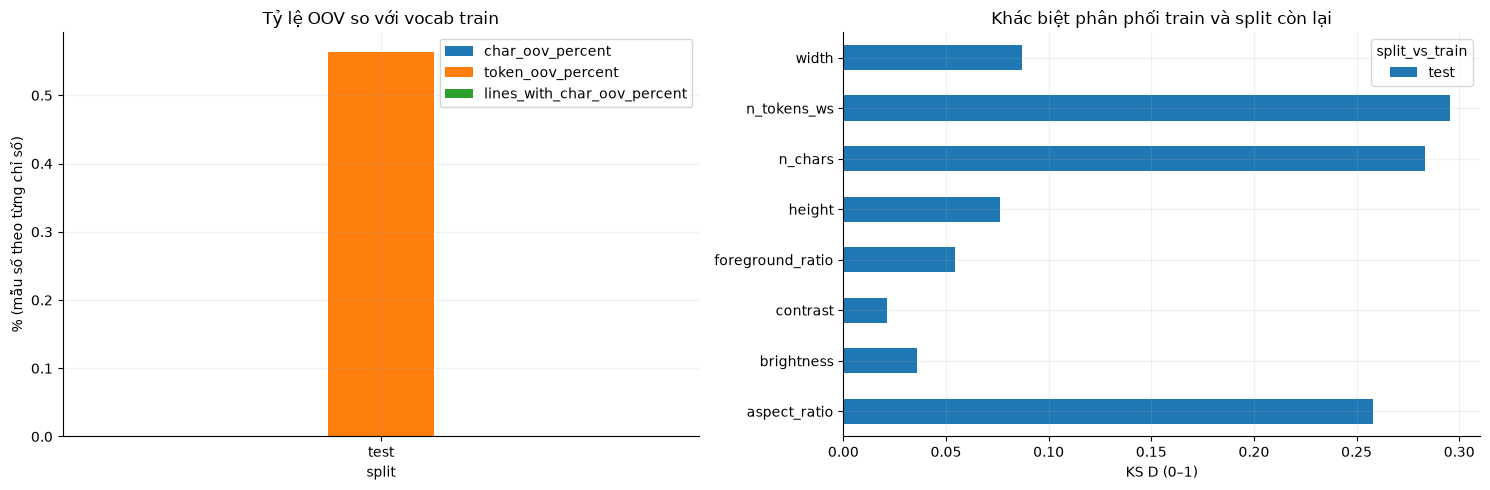

In [13]:
oov_rows, unseen_rows, shift_rows = [], [], []
train_chars = set(char_counts.get('train', {}))
train_tokens = set(token_counts.get('train', {}))
if 'train' in SPLITS:
    for s in SPLITS:
        if s == 'train': continue
        cc, tc = char_counts[s], token_counts[s]
        unseen_c, unseen_t = set(cc)-train_chars, set(tc)-train_tokens
        subset = df[df.split.eq(s)]
        oov_rows.append({'split': s, 'unseen_char_types': len(unseen_c),
            'char_oov_occurrences': sum(cc[c] for c in unseen_c),
            'char_oov_percent': 100*sum(cc[c] for c in unseen_c)/max(1, sum(cc.values())),
            'lines_with_char_oov_percent': 100*subset.text_nfc.map(lambda t: bool(set(t)-train_chars)).mean(),
            'unseen_token_types': len(unseen_t),
            'token_oov_percent': 100*sum(tc[t] for t in unseen_t)/max(1, sum(tc.values())),
            'lines_with_token_oov_percent': 100*subset.text_nfc.map(lambda t: bool(
                set(re.findall(r'[^\W\d_]+', t.lower()))-train_tokens)).mean()})
        unseen_rows += [{'split': s, 'character': c, 'codepoint': f'U+{ord(c):04X}',
                         'count': cc[c]} for c in sorted(unseen_c)]
        for col in ['n_chars', 'n_tokens_ws', 'width', 'height', 'aspect_ratio',
                    'brightness', 'contrast', 'foreground_ratio']:
            frame = df if col in ['n_chars', 'n_tokens_ws'] else valid
            a = frame.loc[frame.split.eq('train'), col].dropna()
            b = frame.loc[frame.split.eq(s), col].dropna()
            if len(a) and len(b):
                ks = ks_2samp(a, b, method='asymp')
                shift_rows.append({'split_vs_train': s, 'metric': col, 'n_train': len(a), 'n_other': len(b),
                    'median_train': a.median(), 'median_other': b.median(),
                    'median_difference': b.median()-a.median(), 'KS_D': ks.statistic,
                    'KS_p_reference_only': ks.pvalue})
        keys = sorted(train_chars | set(cc))
        a = np.array([char_counts['train'][k] for k in keys], dtype=float)
        b = np.array([cc[k] for k in keys], dtype=float)
        if a.sum() and b.sum():
            note(f'Jensen–Shannon distance ký tự **train ↔ {s}: {jensenshannon(a, b, base=2):.4f}**.')
oov = pd.DataFrame(oov_rows)
shift = pd.DataFrame(shift_rows)
table(oov, 'oov_against_train')
table(pd.DataFrame(unseen_rows, columns=['split', 'character', 'codepoint', 'count']), 'unseen_characters', 100)
table(shift, 'distribution_shift')
fig, axs = plt.subplots(1, 2, figsize=(15, 5))
if not oov.empty:
    oov.set_index('split')[['char_oov_percent', 'token_oov_percent',
                           'lines_with_char_oov_percent']].plot.bar(ax=axs[0], rot=0)
    axs[0].set(title='Tỷ lệ OOV so với vocab train', ylabel='% (mẫu số theo từng chỉ số)')
if not shift.empty:
    shift.pivot(index='metric', columns='split_vs_train', values='KS_D').plot.barh(ax=axs[1])
    axs[1].set(title='Khác biệt phân phối train và split còn lại', xlabel='KS D (0–1)', ylabel='')
finish(fig, '15_oov_distribution_shift')

In [14]:
# Nội dung lặp theo nhóm thư mục: chỉ áp dụng nếu nguồn cung cấp group_id.
if df.group_id.notna().any():
    group_stats = df.groupby(['split', 'group_id']).agg(n_lines=('sample_id', 'size'),
        median_chars=('n_chars', 'median'), mean_chars=('n_chars', 'mean')).reset_index()
    table(group_stats, 'directory_group_statistics')
    fig, axs = plt.subplots(1, 2, figsize=(14, 5))
    for s in SPLITS:
        g = group_stats[group_stats.split.eq(s)]
        axs[0].hist(g.n_lines, bins=20, histtype='step', linewidth=2, label=s, color=COLORS.get(s))
    axs[0].set(title='Số dòng trong một nhóm thư mục', xlabel='Số dòng', ylabel='Số nhóm'); axs[0].legend()
    top = group_stats.nlargest(20, 'n_lines').copy()
    top['label'] = top.split + '/' + top.group_id.astype(str)
    axs[1].barh(top.label.iloc[::-1], top.n_lines.iloc[::-1], color='#2266AA')
    axs[1].set(title='20 nhóm có nhiều dòng nhất', xlabel='Số dòng')
    finish(fig, '16_directory_group_distribution')
    group_sets = {s: set(df.loc[df.split.eq(s), 'group_id'].dropna()) for s in SPLITS}
    if 'train' in SPLITS and 'test' in SPLITS:
        common_groups = group_sets['train'] & group_sets['test']
        note(f'Có **{len(common_groups)} mã thư mục** đồng thời xuất hiện trong train và test. '
             'Mã thư mục không có metadata xác nhận là ID người viết; chưa thể kết luận chia theo người viết.')
    group_note = f'Có {len(group_stats):,} nhóm thư mục tính riêng theo split; chưa xác nhận danh tính người viết.'
else:
    group_note = 'Nguồn cục bộ không cung cấp ID người viết/trang; không đánh giá được writer-independent split.'
    note(group_note)

Nguồn cục bộ không cung cấp ID người viết/trang; không đánh giá được writer-independent split.

## 10. Hệ quả đối với resize, padding, batching và CTC

Mô phỏng giữ tỷ lệ ở chiều cao 32 px: `W_resized = ceil(W × 32 / H)`.
Ngưỡng chiều rộng được chọn theo phân vị **train**; báo tỷ lệ các split vượt ngưỡng,
không tự crop ảnh. Nếu thực sự crop, các dòng vượt ngưỡng có nguy cơ mất chữ; có thể dùng
bucket theo chiều rộng hoặc giữ đầy đủ rồi padding.

Với CTC ký tự, điều kiện cần là `T ≥ L + R`, trong đó L là số ký tự NFC gồm khoảng trắng,
R là số cặp ký tự kề nhau giống nhau. Số bước `floor(W_resized / stride)` chỉ là mô phỏng bảo thủ;
cần tính lại bằng công thức output của CNN thực tế. Không áp dụng kết luận CTC này cho decoder attention.
So sánh padding trên ảnh train đọc được, lấy tối đa 20.000 mẫu: random batching và bucket sắp theo rộng;
bucket toàn cục là mốc tham chiếu tiết kiệm, khi huấn luyện vẫn cần xáo trộn batch.

,train_quantile,width_cap,split,n_exceed,exceed_percent
0,0.90,495,train,5902,9.961686
1,0.90,495,test,211,21.100000
2,0.95,566,train,2953,4.984219
3,0.95,566,test,112,11.200000
4,0.99,744,train,588,0.992455
5,0.99,744,test,28,2.800000
6,1.00,1312,train,0,0.000000
7,1.00,1312,test,0,0.000000


,split,stride,n,n_insufficient,insufficient_percent
0,train,4,59247,191,0.322379
1,test,4,1000,2,0.200000
2,train,8,59247,31920,53.876146
3,test,8,1000,549,54.900000
4,train,16,59247,59143,99.824464
5,test,16,1000,999,99.900000


,batch_size,strategy,n_images,padding_waste_percent
0,8,random,20000,34.096578
1,8,bucket_sorted,20000,0.070899
2,16,random,20000,41.279039
3,16,bucket_sorted,20000,0.155304
4,32,random,20000,47.108400
5,32,bucket_sorted,20000,0.331933
6,64,random,20000,51.753836
7,64,bucket_sorted,20000,0.505052


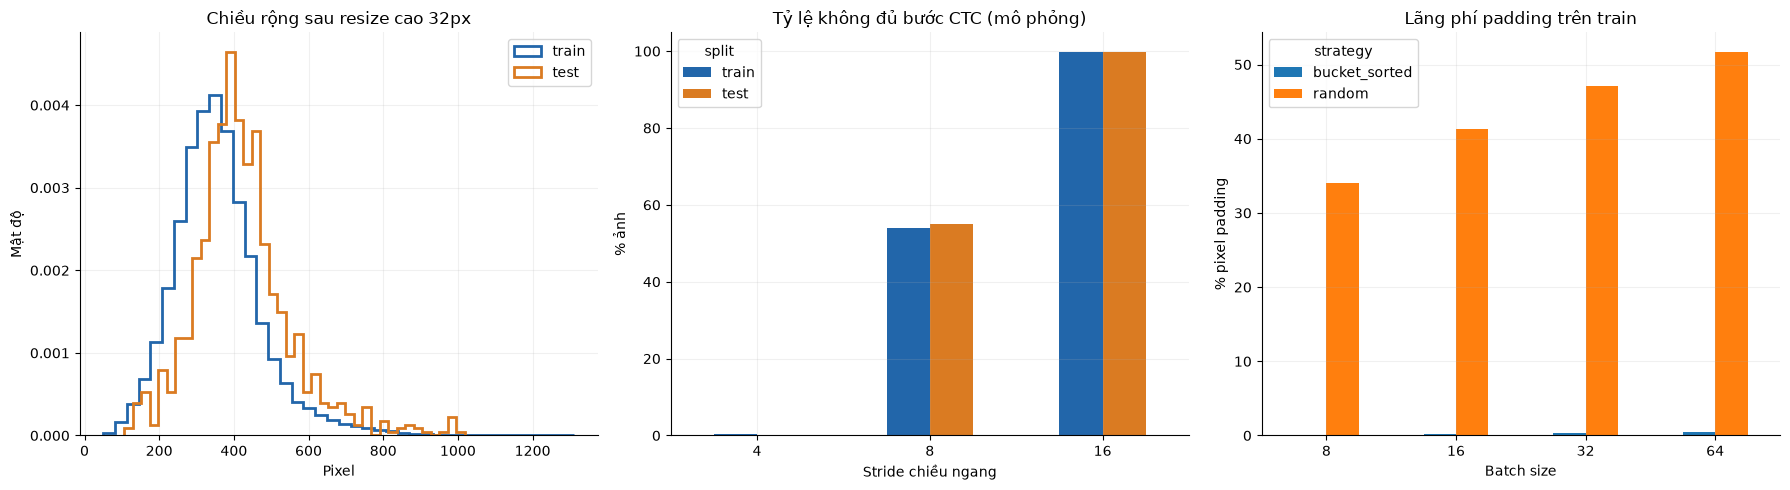

In [15]:
valid['resized_width'] = np.ceil(valid.width * TARGET_HEIGHT / valid.height).astype(int)
train_images = valid[valid.split.eq('train')]
cap_rows = []
if len(train_images):
    for q in [.90, .95, .99, 1.0]:
        cap = int(np.ceil(train_images.resized_width.quantile(q)))
        for s in SPLITS:
            sub = valid[valid.split.eq(s)]
            if len(sub):
                cap_rows.append({'train_quantile': q, 'width_cap': cap, 'split': s,
                                 'n_exceed': int(sub.resized_width.gt(cap).sum()),
                                 'exceed_percent': 100*sub.resized_width.gt(cap).mean()})
caps = pd.DataFrame(cap_rows)
table(caps, 'width_caps_from_train')
ctc_rows = []
for stride in [4, 8, 16]:
    for s in SPLITS:
        sub = valid[valid.split.eq(s)]
        if len(sub):
            steps = sub.resized_width // stride
            insufficient = steps.lt(sub.ctc_min_steps)
            ctc_rows.append({'split': s, 'stride': stride, 'n': len(sub),
                             'n_insufficient': int(insufficient.sum()),
                             'insufficient_percent': 100*insufficient.mean()})
ctc = pd.DataFrame(ctc_rows)
table(ctc, 'ctc_feasibility_simulation')
train_widths = train_images.resized_width.sample(min(20000, len(train_images)), random_state=SEED).to_numpy()
padding_rows = []
rng = np.random.default_rng(SEED)
for batch_size in [8, 16, 32, 64]:
    for strategy in ['random', 'bucket_sorted']:
        widths = rng.permutation(train_widths) if strategy == 'random' else np.sort(train_widths)
        used, allocated = 0, 0
        for start in range(0, len(widths), batch_size):
            batch = widths[start:start+batch_size]
            if len(batch):
                used += batch.sum(); allocated += batch.max()*len(batch)
        padding_rows.append({'batch_size': batch_size, 'strategy': strategy, 'n_images': len(widths),
                             'padding_waste_percent': 100*(1-used/allocated) if allocated else np.nan})
padding = pd.DataFrame(padding_rows)
table(padding, 'padding_simulation')
fig, axs = plt.subplots(1, 3, figsize=(18, 5))
for s in SPLITS:
    sub = valid[valid.split.eq(s)]
    axs[0].hist(sub.resized_width, bins=40, histtype='step', density=True, linewidth=2,
                label=s, color=COLORS.get(s))
axs[0].set(title=f'Chiều rộng sau resize cao {TARGET_HEIGHT}px', xlabel='Pixel', ylabel='Mật độ'); axs[0].legend()
if not ctc.empty:
    ctc.pivot(index='stride', columns='split', values='insufficient_percent').reindex(columns=SPLITS).plot.bar(
        ax=axs[1], rot=0, color=[COLORS.get(s, '#777777') for s in SPLITS])
axs[1].set(title='Tỷ lệ không đủ bước CTC (mô phỏng)', xlabel='Stride chiều ngang', ylabel='% ảnh')
padding.pivot(index='batch_size', columns='strategy', values='padding_waste_percent').plot.bar(ax=axs[2], rot=0)
axs[2].set(title='Lãng phí padding trên train', xlabel='Batch size', ylabel='% pixel padding')
finish(fig, '17_resize_ctc_padding')

## 11. Kết luận định lượng, giới hạn và xuất kết quả

Các câu bên dưới được sinh từ dữ liệu thực trong lần chạy này. Phần xuất gồm manifest có đặc trưng
từng mẫu, bảng tần suất, ngoại lệ, trùng lặp, OOV, PNG và JSON tóm tắt. File xuất là dữ liệu dẫn xuất,
không thay thế dữ liệu gốc. Không suy đoán giấy phép, xuất xứ hoặc số người viết khi metadata thiếu.

In [16]:
summary = {
    'dataset': DATASET, 'created_at_utc': datetime.now(timezone.utc).isoformat(),
    'seed': SEED, 'image_limit': IMAGE_LIMIT, 'quality_thumbnail_max': list(QUALITY_SIZE),
    'n_labels': len(df), 'n_scanned': len(scan_index), 'n_decoded': len(valid),
    'n_source_issues': len(audit), 'n_empty_labels': int(df.empty_label.sum()),
    'n_invalid_label_types': int((~df.label_valid).sum()),
    'n_unique_characters': len(chars), 'n_unique_tokens': len(tokens),
    'n_cross_split_pixel_groups': len(cross_hashes), 'group_metadata_note': group_note,
    'versions': versions, 'splits': split_counts.to_dict('records'),
    'median_chars': float(df.n_chars.median()),
    'median_width': float(valid.width.median()), 'median_height': float(valid.height.median()),
}
manifest_cols = [c for c in df if not c.startswith('_')]
# Thêm các proxy/cờ chỉ tồn tại trên valid bằng phép join theo sample_id.
extra_cols = ['sample_id', 'chars_per_100px', 'resized_width'] + image_flags
manifest = df[manifest_cols].merge(valid[extra_cols], on='sample_id', how='left', validate='one_to_one')
manifest.to_csv(REPORT_DIR / 'sample_features.csv', index=False, encoding='utf-8-sig')
(REPORT_DIR / 'summary.json').write_text(json.dumps(summary, ensure_ascii=False, indent=2), encoding='utf-8')
lines = [
    f'### Kết quả — {DATASET}',
    f'- Quy mô: **{len(df):,} nhãn**; train/test: ' + ', '.join(f'{r.split}: {r.n_samples:,}' for r in split_counts.itertuples()) + '.',
    f'- Ảnh: **{len(valid):,}** đọc thành công trên **{len(scan_index):,}** đã thử; **{len(scan_index)-len(valid):,}** lỗi giải mã.',
    f'- Nhãn: **{int(df.empty_label.sum()):,}** rỗng; **{int((~df.label_valid).sum()):,}** sai kiểu; **{int(df.nfc_changed.sum()):,}** thay đổi biểu diễn sau NFC.',
    f'- Độ dài dòng: trung vị **{df.n_chars.median():.0f}** ký tự NFC; P95 **{df.n_chars.quantile(.95):.0f}**; tối đa **{df.n_chars.max():,}**.',
    f'- Hình học: trung vị **{valid.width.median():.0f} × {valid.height.median():.0f} px** (hai trung vị riêng); P99 tỷ lệ rộng/cao **{valid.aspect_ratio.quantile(.99):.2f}**.',
    f'- Bảng chữ cái toàn bộ: **{len(chars):,}** ký tự; train: **{len(train_chars):,}** ký tự.',
    f'- Cùng pixel RGB xuất hiện ở nhiều split: **{len(cross_hashes):,} nhóm**; cùng pixel nhưng nhãn khác: **{len(conflict_hashes):,} nhóm**.',
    f'- Metadata nhóm: {group_note}',
]
if not oov.empty:
    lines += [f'- {r.split}: OOV ký tự **{r.char_oov_percent:.3f}%** lượt; **{r.lines_with_char_oov_percent:.2f}%** dòng chứa ký tự chưa gặp ở train.' for r in oov.itertuples()]
if not shift.empty:
    strongest = shift.sort_values('KS_D', ascending=False).iloc[0]
    lines.append(f'- Trong các đại lượng đã kiểm tra, KS D lớn nhất là **{strongest.KS_D:.3f}** ở **{strongest.metric}**, so sánh train và {strongest.split_vs_train}.')
lines += [
    '', '**Hướng xử lý cho nghiên cứu:**',
    '- Rà soát nhãn rỗng, sai kiểu, ký tự điều khiển, ảnh lỗi và các nhóm cùng pixel/khác nhãn trước khi huấn luyện.',
    '- Nếu xác nhận ảnh trùng giữa split, lập phiên bản split mới có ghi nhận; giữ nguyên bộ test gốc khi cần đối chiếu benchmark công bố.',
    '- Xây vocab/normalizer và chọn kích thước đầu vào từ train. Với OOV test, báo CER trên toàn bộ test và cách xử lý ký tự chưa biết.',
    '- Dùng bucket chiều rộng; kiểm tra output length CNN và min steps CTC thực tế. Không cắt dòng dài mà giữ nguyên nhãn.',
    '- CER/WER và độ chính xác cần dự đoán của mô hình và nhãn chuẩn; notebook EDA không đo những chỉ số đó.',
    '', '**Giới hạn:** nhãn chưa được kiểm chứng thủ công toàn bộ; không xác nhận danh tính người viết, bản quyền '
    'hoặc nguồn thu thập chỉ từ cấu trúc thư mục. Proxy chất lượng phụ thuộc nền/resize. '
    'Hash pixel chỉ phát hiện bản sao chính xác sau chuyển RGB; không bao phủ ảnh crop, nén lại, nghiêng hay bản sao gần giống. '
    'Không có khoảng tin cậy suy rộng vì chưa có thiết kế lấy mẫu độc lập theo người viết.',
    '', f'Kết quả lưu tại: `{REPORT_DIR}`.'
]
report_text = '\n'.join(lines)
note(report_text)
(REPORT_DIR / 'analysis_summary.md').write_text(report_text, encoding='utf-8')
table(pd.DataFrame({'figure': sorted(set(FIGURES))}), 'figure_index', 100)
print('Đã lưu', len(list(REPORT_DIR.glob('*.csv'))), 'bảng CSV và', len(set(FIGURES)), 'hình PNG.')

### Kết quả — viet_htr
- Quy mô: **60,247 nhãn**; train/test: train: 59,247, test: 1,000.
- Ảnh: **60,247** đọc thành công trên **60,247** đã thử; **0** lỗi giải mã.
- Nhãn: **0** rỗng; **0** sai kiểu; **1** thay đổi biểu diễn sau NFC.
- Độ dài dòng: trung vị **45** ký tự NFC; P95 **72**; tối đa **166**.
- Hình học: trung vị **635 × 59 px** (hai trung vị riêng); P99 tỷ lệ rộng/cao **23.30**.
- Bảng chữ cái toàn bộ: **404** ký tự; train: **404** ký tự.
- Cùng pixel RGB xuất hiện ở nhiều split: **0 nhóm**; cùng pixel nhưng nhãn khác: **0 nhóm**.
- Metadata nhóm: Nguồn cục bộ không cung cấp ID người viết/trang; không đánh giá được writer-independent split.
- test: OOV ký tự **0.000%** lượt; **0.00%** dòng chứa ký tự chưa gặp ở train.
- Trong các đại lượng đã kiểm tra, KS D lớn nhất là **0.295** ở **n_tokens_ws**, so sánh train và test.

**Hướng xử lý cho nghiên cứu:**
- Rà soát nhãn rỗng, sai kiểu, ký tự điều khiển, ảnh lỗi và các nhóm cùng pixel/khác nhãn trước khi huấn luyện.
- Nếu xác nhận ảnh trùng giữa split, lập phiên bản split mới có ghi nhận; giữ nguyên bộ test gốc khi cần đối chiếu benchmark công bố.
- Xây vocab/normalizer và chọn kích thước đầu vào từ train. Với OOV test, báo CER trên toàn bộ test và cách xử lý ký tự chưa biết.
- Dùng bucket chiều rộng; kiểm tra output length CNN và min steps CTC thực tế. Không cắt dòng dài mà giữ nguyên nhãn.
- CER/WER và độ chính xác cần dự đoán của mô hình và nhãn chuẩn; notebook EDA không đo những chỉ số đó.

**Giới hạn:** nhãn chưa được kiểm chứng thủ công toàn bộ; không xác nhận danh tính người viết, bản quyền hoặc nguồn thu thập chỉ từ cấu trúc thư mục. Proxy chất lượng phụ thuộc nền/resize. Hash pixel chỉ phát hiện bản sao chính xác sau chuyển RGB; không bao phủ ảnh crop, nén lại, nghiêng hay bản sao gần giống. Không có khoảng tin cậy suy rộng vì chưa có thiết kế lấy mẫu độc lập theo người viết.

Kết quả lưu tại: `D:\2026_1\deep_learning\ocr-vietnamese\reports\results\eda\viet_htr`.

,figure
0,01_split_counts
1,02_label_quality
2,03_text_length_distributions
3,04_characters_tokens_zipf
4,05_tones_unicode_categories
5,06_image_distributions
6,07_image_geometry_text_relations
7,08_correlation_heatmap
8,09_random_gallery
9,10_extreme_lengths_gallery


Đã lưu 38 bảng CSV và 15 hình PNG.


## 12. So sánh hai bộ dữ liệu (tự chạy khi đã có kết quả của notebook còn lại)

Chạy cả hai notebook, rồi chạy lại riêng ô dưới ở notebook chạy trước để có so sánh hai chiều.
Đọc kết quả đã xuất, không giải mã lại ảnh. Bảng so sánh gồm quy mô, độ dài, hình học, ký tự,
giao nhãn và giao pixel giữa hai nguồn (kể cả giao **train nguồn này ↔ test nguồn kia**).
Nếu hai bản xuất có thời điểm/độ phủ khác nhau, cần chạy lại cả hai trước khi dùng trong báo cáo.

,dataset,n_labels,n_scanned,n_decoded,median_chars,median_width,median_height,n_unique_characters,n_cross_split_pixel_groups,created_at_utc
0,viet_htr,60247,60247,60247,45.0,635.0,59.0,404,0,2026-11-01T04:29:24.609484+00:00
1,UIT_HWDB_line,7229,7229,7229,71.0,2048.0,152.0,161,0,2026-11-01T04:27:14.594379+00:00


,dataset_a,split_a,dataset_b,split_b,key,shared_unique_values
0,viet_htr,train,UIT_HWDB_line,test,text_compare,0
1,viet_htr,train,UIT_HWDB_line,test,sha256_pixels,0
2,viet_htr,train,UIT_HWDB_line,train,text_compare,0
3,viet_htr,train,UIT_HWDB_line,train,sha256_pixels,0
4,viet_htr,test,UIT_HWDB_line,test,text_compare,0
5,viet_htr,test,UIT_HWDB_line,test,sha256_pixels,0
6,viet_htr,test,UIT_HWDB_line,train,text_compare,0
7,viet_htr,test,UIT_HWDB_line,train,sha256_pixels,0


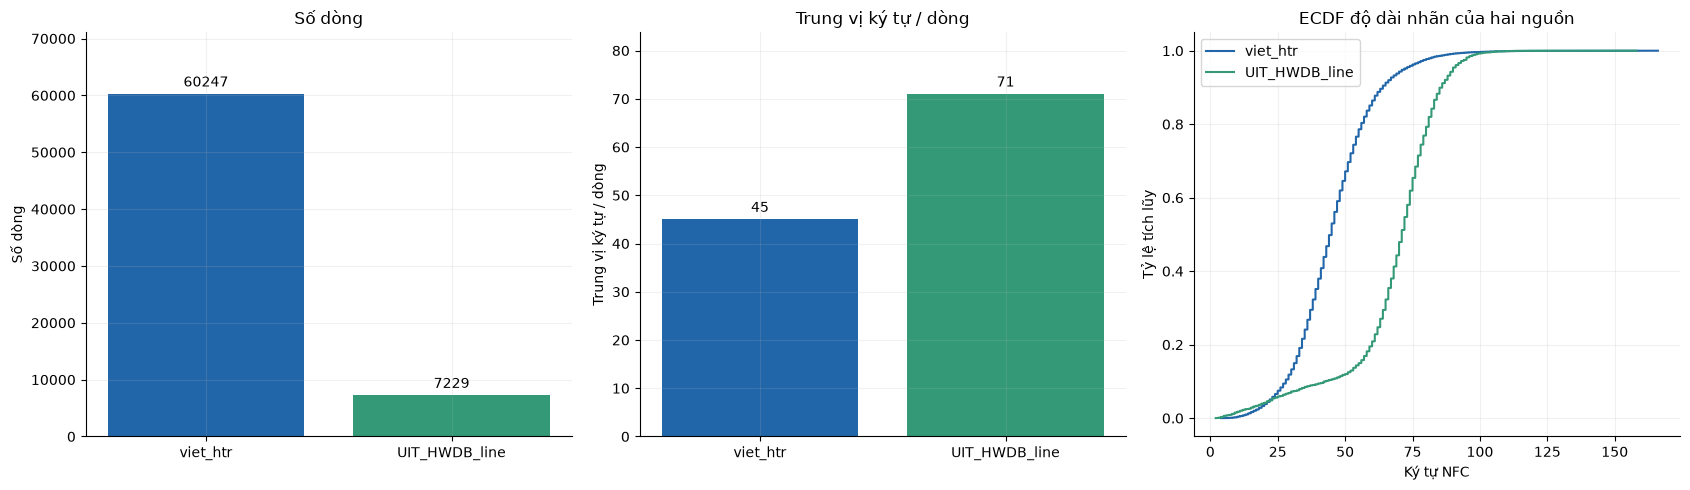

Ảnh giống pixel giữa hai nguồn cần được kiểm tra trước khi gộp train/test. Giao nhãn không tự chứng minh hai nguồn độc lập hoặc trùng ảnh. Thời điểm xuất của nguồn kia: **2026-11-01T04:27:14.594379+00:00**; độ phủ ảnh: **7,229/7,229**.

In [17]:
OTHER = 'viet_htr' if DATASET == 'UIT_HWDB_line' else 'UIT_HWDB_line'
OTHER_DIR = REPORT_DIR.parent / OTHER
if not (OTHER_DIR / 'sample_features.csv').exists() or not (OTHER_DIR / 'summary.json').exists():
    note(f'Chưa có kết quả của **{OTHER}**. Chạy notebook đó rồi chạy lại ô này để so sánh.')
else:
    other_summary = json.loads((OTHER_DIR / 'summary.json').read_text(encoding='utf-8'))
    other = pd.read_csv(OTHER_DIR / 'sample_features.csv', keep_default_na=False,
                        usecols=['sample_id', 'split', 'text_compare', 'n_chars', 'sha256_pixels'])
    comparison = pd.DataFrame([summary, other_summary])[
        ['dataset', 'n_labels', 'n_scanned', 'n_decoded', 'median_chars', 'median_width',
         'median_height', 'n_unique_characters', 'n_cross_split_pixel_groups', 'created_at_utc']]
    table(comparison, 'two_datasets_summary')
    cross_dataset = []
    for a in SPLITS:
        for b in sorted(other.split.unique()):
            for key, source in [('text_compare', df), ('sha256_pixels', valid)]:
                aset = set(source.loc[source.split.eq(a), key].dropna()) - {''}
                bset = set(other.loc[other.split.eq(b), key].dropna()) - {''}
                cross_dataset.append({'dataset_a': DATASET, 'split_a': a,
                                      'dataset_b': OTHER, 'split_b': b, 'key': key,
                                      'shared_unique_values': len(aset & bset)})
    cross_dataset = pd.DataFrame(cross_dataset)
    table(cross_dataset, 'cross_dataset_overlap')
    fig, axs = plt.subplots(1, 3, figsize=(17, 5))
    for ax, metric, label in zip(axs[:2], ['n_labels', 'median_chars'], ['Số dòng', 'Trung vị ký tự / dòng']):
        bars = ax.bar(comparison.dataset, comparison[metric], color=['#2266AA', '#339977'])
        ax.bar_label(bars, fmt='%.0f', padding=3); ax.margins(y=.18); ax.set(title=label, ylabel=label)
    for name, frame in [(DATASET, df), (OTHER, other)]:
        x = np.sort(pd.to_numeric(frame.n_chars).to_numpy())
        axs[2].plot(x, np.arange(1, len(x)+1)/len(x), label=name,
                    color='#2266AA' if name == DATASET else '#339977')
    axs[2].set(title='ECDF độ dài nhãn của hai nguồn', xlabel='Ký tự NFC', ylabel='Tỷ lệ tích lũy')
    axs[2].legend()
    finish(fig, '18_two_dataset_comparison')
    note('Ảnh giống pixel giữa hai nguồn cần được kiểm tra trước khi gộp train/test. '
         'Giao nhãn không tự chứng minh hai nguồn độc lập hoặc trùng ảnh. '
         f'Thời điểm xuất của nguồn kia: **{other_summary["created_at_utc"]}**; '
         f'độ phủ ảnh: **{other_summary["n_scanned"]:,}/{other_summary["n_labels"]:,}**.')

## 13. Phân tích sâu: ngoại lệ thống kê, đuôi dài và dấu phụ tiếng Việt

Phần này bổ sung cách đọc các thống kê cho báo cáo nghiên cứu. Độ lệch (skewness), độ nhọn dư
(excess kurtosis), hệ số biến thiên (CV = std/mean) và khoảng tứ phân vị (IQR) giúp mô tả hình dạng
phân phối. Quy tắc Tukey xác định ngoại lệ ngoài [Q1−1,5IQR; Q3+1,5IQR] **riêng từng split**.
Ngoại lệ không đồng nghĩa dữ liệu lỗi, đặc biệt với các dòng kết thúc đoạn ngắn.

In [18]:
analysis_df = pd.read_csv(REPORT_DIR / 'sample_features.csv', keep_default_na=False)
numeric_rows, outlier_parts = [], []
for split, group in analysis_df.groupby('split'):
    for metric in ['n_chars', 'n_tokens_ws', 'width', 'height', 'aspect_ratio', 'contrast', 'foreground_ratio']:
        values = pd.to_numeric(group[metric], errors='coerce').dropna()
        if values.empty:
            continue
        q1, q3 = values.quantile([.25, .75]); iqr = q3-q1
        lower, upper = q1-1.5*iqr, q3+1.5*iqr
        outside = values.lt(lower) | values.gt(upper)
        numeric_rows.append({'split': split, 'metric': metric, 'n': len(values),
            'mean': values.mean(), 'variance_ddof1': values.var(), 'std_ddof1': values.std(),
            'CV': values.std()/values.mean() if values.mean() != 0 else np.nan,
            'skewness': values.skew(), 'excess_kurtosis': values.kurt(),
            'Q1': q1, 'Q3': q3, 'IQR': iqr, 'lower_fence': lower, 'upper_fence': upper,
            'n_outside_IQR': int(outside.sum()), 'outside_IQR_percent': 100*outside.mean()})
        if outside.any():
            out = group.loc[values[outside].index, ['sample_id', 'split', 'text_nfc']].copy()
            out['metric'] = metric; out['value'] = values[outside]
            out['lower_fence'] = lower; out['upper_fence'] = upper
            outlier_parts.append(out)
detailed_stats = pd.DataFrame(numeric_rows)
table(detailed_stats, 'distribution_shapes_and_iqr', 50)
outlier_table = pd.concat(outlier_parts, ignore_index=True) if outlier_parts else pd.DataFrame(
    columns=['sample_id', 'split', 'text_nfc', 'metric', 'value', 'lower_fence', 'upper_fence'])
table(outlier_table, 'iqr_outlier_candidates', 15)
if not audit.empty:
    issue_counts = audit.groupby('kind').size().rename('count').sort_values(ascending=False).reset_index()
    table(issue_counts, 'source_issue_counts')
    fig, ax = plt.subplots(figsize=(10, 4))
    bars = ax.barh(issue_counts.kind.iloc[::-1], issue_counts['count'].iloc[::-1], color='#B84A44')
    ax.bar_label(bars, padding=4); ax.margins(x=.15)
    ax.set(title='Kiểm kê vấn đề cấu trúc nguồn', xlabel='Số vấn đề được ghi nhận', ylabel='')
    finish(fig, '19_source_integrity_issues')
    note('Chi tiết vấn đề cấu trúc: ' + '; '.join(f'**{r.kind}: {r.count:,}**' for r in issue_counts.itertuples()) +
         '. Ảnh không có nhãn không được đưa vào các thống kê cặp ảnh–nhãn hoặc kiểm tra hash ở các phần trước.')
else:
    note('Không ghi nhận lỗi cấu trúc nguồn trong các kiểm tra loader đã thực hiện.')
for r in detailed_stats[detailed_stats.metric.eq('n_chars')].itertuples():
    direction = 'lệch phải' if r.skewness > .1 else ('lệch trái' if r.skewness < -.1 else 'gần đối xứng theo skewness')
    note(f'**{r.split} — độ dài nhãn:** skewness = **{r.skewness:.3f}** ({direction}); '
         f'CV = **{r.CV:.3f}**; **{r.n_outside_IQR:,}/{r.n:,}** dòng nằm ngoài hàng rào IQR '
         f'(**{r.outside_IQR_percent:.2f}%**). Đây là mô tả hình dạng, không phải kiểm định tính chuẩn.')

,split,metric,n,mean,variance_ddof1,std_ddof1,CV,skewness,excess_kurtosis,Q1,Q3,IQR,lower_fence,upper_fence,n_outside_IQR,outside_IQR_percent
0,test,n_chars,1000,53.638000,257.994951,16.062221,0.299456,0.846920,3.405854,45.000000,60.000000,15.000000,22.500000,82.500000,72,7.200000
1,test,n_tokens_ws,1000,12.911000,13.999078,3.741534,0.289794,0.578459,2.464423,11.000000,15.000000,4.000000,5.000000,21.000000,31,3.100000
2,test,width,1000,764.944000,154876.014879,393.542901,0.514473,1.827703,5.792345,504.750000,918.250000,413.500000,-115.500000,1538.500000,50,5.000000
3,test,height,1000,61.339000,1235.629709,35.151525,0.573070,2.677711,12.473996,39.000000,73.000000,34.000000,-12.000000,124.000000,45,4.500000
4,test,aspect_ratio,1000,13.176049,16.924690,4.113963,0.312230,1.064668,2.741944,10.781359,14.927995,4.146636,4.561404,21.147950,52,5.200000
5,test,contrast,1000,30.595676,108.810833,10.431243,0.340938,0.865653,1.078143,23.319981,36.355287,13.035306,3.767022,55.908246,18,1.800000
6,test,foreground_ratio,1000,0.193263,0.015315,0.123752,0.640329,3.019352,10.994936,0.128015,0.201470,0.073455,0.017832,0.311652,100,10.000000
7,train,n_chars,59247,45.382332,222.747686,14.924734,0.328867,0.641030,1.590297,36.000000,54.000000,18.000000,9.000000,81.000000,1277,2.155383
8,train,n_tokens_ws,59247,10.892906,12.527116,3.539367,0.324924,0.505334,1.137899,9.000000,13.000000,4.000000,3.000000,19.000000,1388,2.342735
9,train,width,59247,715.927794,175774.139572,419.254266,0.585610,2.946850,16.701537,461.000000,876.000000,415.000000,-161.500000,1498.500000,2541,4.288825


,sample_id,split,text_nfc,metric,value,lower_fence,upper_fence
0,test/0000003,test,trục Oz và cách trục Oz một khoảng bằng 3. Khi...,n_chars,97.0,22.5,82.5
1,test/0000008,test,"- Phương pháp, thủ thuật, kỹ thuật, thuốc đã s...",n_chars,112.0,22.5,82.5
2,test/0000013,test,"và những cán bộ ưu tú của Đảng, Nhà nước và nh...",n_chars,84.0,22.5,82.5
3,test/0000032,test,Thể tích vật đó là:,n_chars,19.0,22.5,82.5
4,test/0000054,test,Vì mục đích nhân đạo và được sự nhất trí của t...,n_chars,87.0,22.5,82.5
5,test/0000059,test,"được, thì các bên có quyền khởi kiện để yêu cầ...",n_chars,97.0,22.5,82.5
6,test/0000069,test,hàng. Vì vậy Công ty cổ phần sản xuất & thương...,n_chars,106.0,22.5,82.5
7,test/0000089,test,Ta có: OM=OC=R,n_chars,14.0,22.5,82.5
8,test/0000105,test,"Đã không ngại khó khăn, nguy hiểm để truy bắt ...",n_chars,89.0,22.5,82.5
9,test/0000115,test,được lập thành 03 bản: 01 bản giao cho cá nhân...,n_chars,90.0,22.5,82.5


Không ghi nhận lỗi cấu trúc nguồn trong các kiểm tra loader đã thực hiện.

**test — độ dài nhãn:** skewness = **0.847** (lệch phải); CV = **0.299**; **72/1,000** dòng nằm ngoài hàng rào IQR (**7.20%**). Đây là mô tả hình dạng, không phải kiểm định tính chuẩn.

**train — độ dài nhãn:** skewness = **0.641** (lệch phải); CV = **0.329**; **1,277/59,247** dòng nằm ngoài hàng rào IQR (**2.16%**). Đây là mô tả hình dạng, không phải kiểm định tính chuẩn.

### 13.1. Mức tập trung ký tự/token và độ bao phủ

Dùng **train** để đo cần bao nhiêu loại ký tự/token phổ biến nhất để phủ 80%, 90%, 95%, 99%
**lượt xuất hiện**. Độ bao phủ lượt không đảm bảo phủ mọi dòng, và không đủ lý do loại bỏ các ký tự
hiếm khỏi vocab. Gini được tính trên tần suất của những loại đã xuất hiện trong train (không thêm loại
có tần suất 0); Gini gần 1 nghĩa là tần suất tập trung vào ít loại. Ký tự bao gồm khoảng trắng.

,unit,occurrence_coverage_percent,top_k_types_needed,total_types_train,type_fraction_percent
0,ký tự,80.0,31,404,7.673267
1,ký tự,90.0,55,404,13.613861
2,ký tự,95.0,76,404,18.811881
3,ký tự,99.0,118,404,29.207921
4,token chữ,80.0,688,10773,6.386336
5,token chữ,90.0,1235,10773,11.463845
6,token chữ,95.0,2004,10773,18.602061
7,token chữ,99.0,5344,10773,49.605495


,unit,gini_over_observed_types,top10_occurrence_percent
0,ký tự,0.911086,59.023746
1,token chữ,0.905310,10.202412


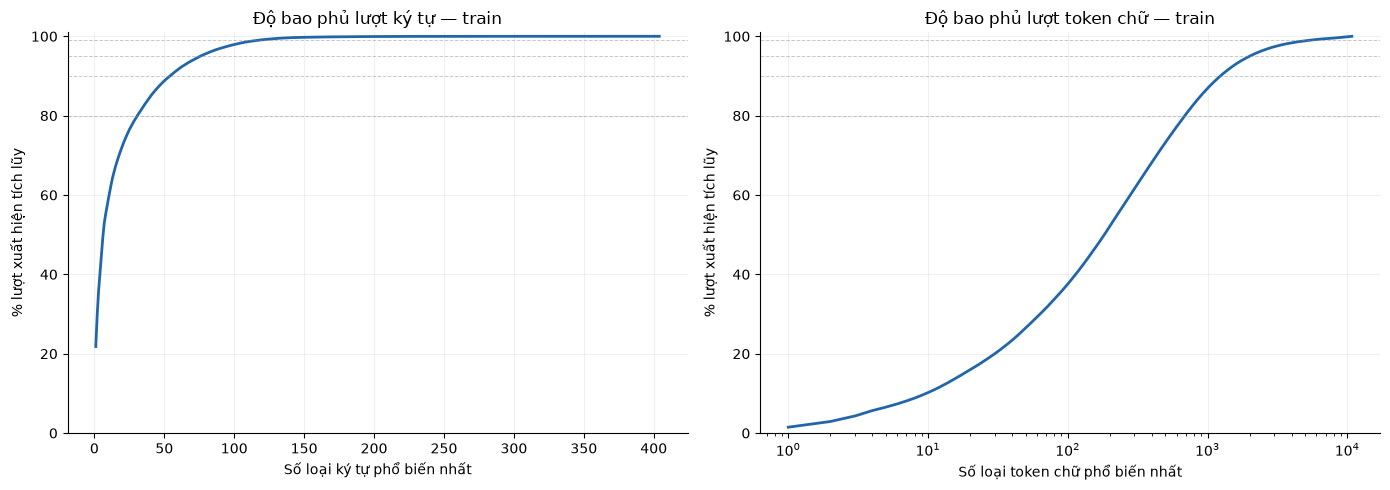

In [19]:
coverage_rows, concentration = [], []
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
if 'train' in SPLITS:
    for ax, counters, name in [(axs[0], char_counts, 'ký tự'), (axs[1], token_counts, 'token chữ')]:
        frequencies = np.array(sorted(counters['train'].values(), reverse=True), dtype=float)
        if not frequencies.size or not frequencies.sum():
            continue
        cumulative = np.cumsum(frequencies)/frequencies.sum()
        ax.plot(np.arange(1, len(frequencies)+1), cumulative*100, color='#2266AA', linewidth=2)
        for target in [.80, .90, .95, .99]:
            k = int(np.searchsorted(cumulative, target)+1)
            coverage_rows.append({'unit': name, 'occurrence_coverage_percent': target*100,
                                 'top_k_types_needed': k, 'total_types_train': len(frequencies),
                                 'type_fraction_percent': 100*k/len(frequencies)})
            ax.axhline(target*100, color='#888888', linewidth=.7, linestyle='--', alpha=.45)
        ascending = np.sort(frequencies); n = len(ascending)
        gini = (2*np.dot(np.arange(1, n+1), ascending)/(n*ascending.sum()))-(n+1)/n
        concentration.append({'unit': name, 'gini_over_observed_types': gini,
                               'top10_occurrence_percent': 100*frequencies[:10].sum()/frequencies.sum()})
        ax.set(title=f'Độ bao phủ lượt {name} — train', xlabel=f'Số loại {name} phổ biến nhất',
               ylabel='% lượt xuất hiện tích lũy', ylim=(0, 101))
        if name == 'token chữ': ax.set_xscale('log')
    table(pd.DataFrame(coverage_rows), 'train_vocabulary_coverage')
    table(pd.DataFrame(concentration), 'train_frequency_concentration')
finish(fig, '20_train_vocabulary_coverage')

### 13.2. Phân bố nguyên âm có dấu phụ và dấu thanh

Tách **dấu thanh** (huyền, sắc, hỏi, ngã, nặng) khỏi **dấu phụ tạo chữ cái** (ă, â, ê, ô, ơ, ư).
Ví dụ “ắ” được xếp vào nguyên âm **ă**, thanh **sắc**. Gộp hoa/thường; giữ nguyên dấu phụ.
Mỗi ô là phần trăm trong **tổng số ký tự nguyên âm của split**, dùng cùng thang màu giữa các split.
Đây là thống kê ký tự nguyên âm; không dùng để suy ra số từ, thanh của từ hoặc tính đúng chính tả.

,split,vowel_base,tone,count,percent_of_vowels_in_split
0,train,a,không dấu thanh,65187,7.621082
1,train,a,huyền,49062,5.735891
2,train,a,sắc,26173,3.059913
3,train,a,hỏi,14741,1.723386
4,train,a,ngã,7522,0.879405
5,train,a,nặng,15144,1.770501
6,train,ă,không dấu thanh,5718,0.668497
7,train,ă,huyền,1972,0.230549
8,train,ă,sắc,5077,0.593557
9,train,ă,hỏi,680,0.079500


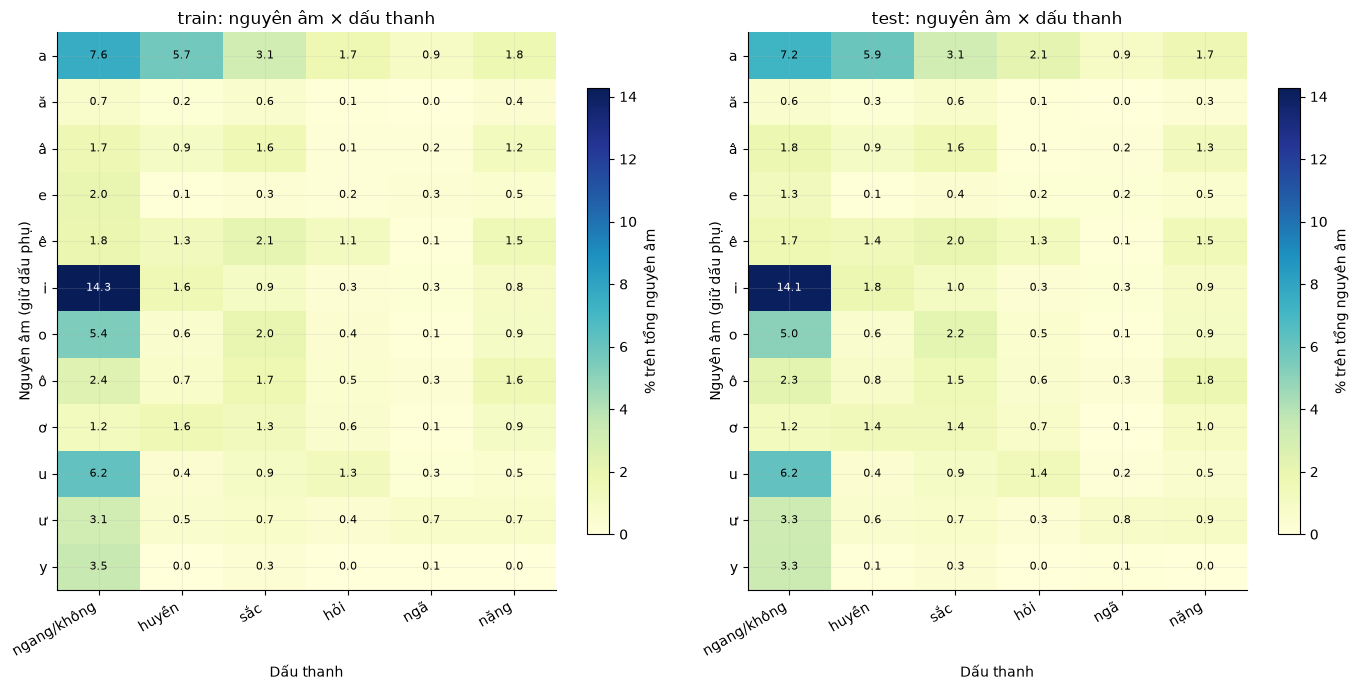

,figure
0,01_split_counts
1,02_label_quality
2,03_text_length_distributions
3,04_characters_tokens_zipf
4,05_tones_unicode_categories
5,06_image_distributions
6,07_image_geometry_text_relations
7,08_correlation_heatmap
8,09_random_gallery
9,10_extreme_lengths_gallery


Tổng cộng **18 hình PNG** được lập chỉ mục. Bảng, ảnh và kết luận chi tiết: `D:\2026_1\deep_learning\ocr-vietnamese\reports\results\eda\viet_htr`.

In [20]:
bases = list('aăâeêioôơuưy')
tones_order = ['không dấu thanh', 'huyền', 'sắc', 'hỏi', 'ngã', 'nặng']
vowel_rows = []
for split in SPLITS:
    counts = Counter()
    for character, count in char_counts[split].items():
        decomposed = unicodedata.normalize('NFD', character.lower())
        base = unicodedata.normalize('NFC', ''.join(c for c in decomposed if c not in TONE_MARKS))
        if base not in bases: continue
        tone = next((TONE_MARKS[c] for c in decomposed if c in TONE_MARKS), 'không dấu thanh')
        counts[(base, tone)] += count
    total = sum(counts.values())
    for base in bases:
        for tone in tones_order:
            n = counts[(base, tone)]
            vowel_rows.append({'split': split, 'vowel_base': base, 'tone': tone, 'count': n,
                               'percent_of_vowels_in_split': 100*n/max(1, total)})
vowel_frame = pd.DataFrame(vowel_rows)
table(vowel_frame, 'vowel_base_tone_distribution', 15)
fig, axs = plt.subplots(1, len(SPLITS), figsize=(7*len(SPLITS), 7), squeeze=False)
maximum = max(1, vowel_frame.percent_of_vowels_in_split.max())
for ax, split in zip(axs.ravel(), SPLITS):
    matrix = vowel_frame[vowel_frame.split.eq(split)].pivot(
        index='vowel_base', columns='tone', values='percent_of_vowels_in_split').reindex(index=bases, columns=tones_order)
    heat = ax.imshow(matrix, cmap='YlGnBu', vmin=0, vmax=maximum, aspect='auto')
    ax.set_xticks(range(len(tones_order)), ['ngang/không', 'huyền', 'sắc', 'hỏi', 'ngã', 'nặng'], rotation=30, ha='right')
    ax.set_yticks(range(len(bases)), bases)
    ax.set(title=f'{split}: nguyên âm × dấu thanh', xlabel='Dấu thanh', ylabel='Nguyên âm (giữ dấu phụ)')
    for i in range(len(bases)):
        for j in range(len(tones_order)):
            value = matrix.iloc[i,j]
            ax.text(j, i, f'{value:.1f}', ha='center', va='center', fontsize=8,
                    color='white' if value > maximum*.55 else 'black')
    fig.colorbar(heat, ax=ax, label='% trên tổng nguyên âm', shrink=.8)
finish(fig, '21_vowel_tone_heatmaps')
table(pd.DataFrame({'figure': sorted(set(FIGURES))}), 'figure_index', 100)
note(f'Tổng cộng **{len(set(FIGURES))} hình PNG** được lập chỉ mục. Bảng, ảnh và kết luận chi tiết: `{REPORT_DIR}`.')